**Kaggle version** (GPU T4 x2) of `smai-mlProject_v3.ipynb`. Same experiment; only the running environment differs:
- data are read from the attached dataset (`/kaggle/input/.../ROD_tracks.pkl`); results are written to `/kaggle/working/unet_seg_v3`;
- the 32 search runs are shared between the GPUs (one worker per GPU, each takes the next waiting run);
- fp16 mixed precision (a T4 has no fast bf16);
- runs saved by an earlier session are reused when that session's output is attached as an input.

On a computer that is not Kaggle it behaves like the local notebook (paths), but still uses every visible GPU.


# Attention Residual U-Net ornament segmentation (ROD), version 3

What this notebook does, step by step:

1. **GPU check**: uses the laptop GPU through the local runtime. If no GPU is visible it stops with an error. It never switches to the CPU.
2. **Cached data only**: loads the saved ROD constant-Q features, frame labels, segments and the original train / validation / test split (137 / 24 / 43 recordings) from `rod_koopman/cache/`.
3. **Classes**: as in version 2, `Mu` and `An` are relabelled as `none`. The model predicts **5 classes**: `none, K, H, Me, G`.
4. **Preprocessing** (unchanged from version 2): silence is removed only at the start and end of each recording, then per-frequency-bin normalisation with training-set statistics.
5. **Model (new)**: an **Attention Residual U-Net**. Every convolution block of the U-Net is a **residual block**, and every skip connection passes through an **attention gate** that learns which time–frequency regions of the encoder features are passed to the decoder. There is no temporal module (TCN / GRU) after the U-Net.
6. **Loss (new)**: ordinary multi-class **cross-entropy**, compared with **focal loss** with γ = 2, 3 and 4 (γ = 0 is exactly cross-entropy).
7. **Hyperparameter search**: 8 configurations (the version-2 selected settings plus 7 random ones), each trained with **all 4 losses**, so every loss is tried on the same configurations. One seed, no seed confirmation. Selection uses the validation set only.
8. **Decoding (new)**: the predicted probabilities are turned into segments with a **1-D watershed** (confident seeds, flooding, one class per segment) instead of the plain per-frame argmax. Its thresholds are tuned on validation after every epoch, and this watershed F1 is used everywhere: checkpointing, the search and the test results.
9. **Epoch-wise images (new)**: the predictions of the final model on two validation recordings are drawn after every training epoch and saved as images.
10. **Test evaluation**: the best model of each loss (chosen on validation) is evaluated once on the held-out test recordings, with both decodings, and compared with version 2.

All results of this version are written to `rod_koopman/unet_seg_v3/`. The results of versions 1 and 2 (`rod_koopman/unet_seg/`, `rod_koopman/unet_seg_v2/`) are left untouched.

## 1. GPU runtime check

In [1]:
import os, sys, time, json, math, random, pickle, gc
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

print('python :', sys.executable)
print('torch  :', torch.__version__, '| CUDA build:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU is visible to PyTorch in this kernel. Stopping instead of falling back to the CPU. '
                       'Check that the notebook is connected to the local runtime that has the CUDA build of torch.')
N_GPU = torch.cuda.device_count()
torch.cuda.set_device(0)
# 'cuda' means the CURRENT GPU of the calling thread: the search runs one worker thread per GPU,
# and each worker selects its own GPU, so all model / data code below runs unchanged on either GPU.
DEV = torch.device('cuda')
_p = torch.cuda.get_device_properties(0)
_free, _total = torch.cuda.mem_get_info()
for _g in range(N_GPU): print(f'GPU {_g}  : {torch.cuda.get_device_properties(_g).name}')
print(f'GPU    : {_p.name} | {_total / 2**30:.2f} GiB total, {_free / 2**30:.2f} GiB free | compute capability {_p.major}.{_p.minor}')
# Recordings have different lengths. cuDNN autotuning would re-benchmark for every new length (very slow), so it is off.
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
# real bf16 needs compute capability >= 8 (Ampere); a T4 (7.5) only emulates it, so fp16 + gradient scaling is used there
AMP_DTYPE = torch.bfloat16 if _p.major >= 8 else torch.float16
print('mixed precision dtype:', AMP_DTYPE)
_a = torch.randn(1024, 1024, device=DEV); _ = float((_a @ _a).sum()); del _a
print('GPU compute check OK')

SEED = 2035
def seed_all(s):
    # seeds the CPU generators and only the CURRENT GPU's generator, so the two search workers do not reset each other
    random.seed(s); np.random.seed(s); torch.default_generator.manual_seed(s); torch.cuda.manual_seed(s)

python : /usr/bin/python3
torch  : 2.11.0+cu130 | CUDA build: 13.0
GPU 0  : Tesla T4
GPU 1  : Tesla T4
GPU    : Tesla T4 | 14.56 GiB total, 14.46 GiB free | compute capability 7.5
mixed precision dtype: torch.float16
GPU compute check OK


## 2. Load the cached features, labels and splits

In [2]:
KAGGLE_IN = Path('/kaggle/input'); KAGGLE = KAGGLE_IN.is_dir()
if KAGGLE:   # data comes from the attached Kaggle dataset; results go to /kaggle/working (downloadable output)
    CACHE = next(KAGGLE_IN.rglob('ROD_tracks.pkl')).parent
    PROJ = Path('/kaggle/working')
else:
    PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rod_koopman' / 'cache').is_dir())
    CACHE = PROJ / 'rod_koopman' / 'cache'
# Version-3 results go to a NEW folder, so the experiments of versions 1 and 2 are never overwritten.
# (UNET_OUT and UNET_SMOKE are only set for a quick end-to-end test of the code; a normal run does not need them.)
OUT = Path(os.environ.get('UNET_OUT', PROJ / 'unet_seg_v3' if KAGGLE else PROJ / 'rod_koopman' / 'unet_seg_v3')); OUT.mkdir(parents=True, exist_ok=True)
RUNS = OUT / 'runs'; RUNS.mkdir(exist_ok=True)
if KAGGLE:   # resume: runs saved by an earlier session (its output attached as an input) are reused, not retrained
    import shutil
    _old = [f for f in KAGGLE_IN.rglob('ROD_attres_*') if f.parent.name == 'runs' and not (RUNS / f.name).exists()]
    for f in _old: shutil.copy2(f, RUNS / f.name)
    print(f'resumed {len(_old)} saved run files from earlier sessions')
SMOKE = os.environ.get('UNET_SMOKE') == '1'
print('cache :', CACHE); print('output:', OUT)
if SMOKE: print('*** SMOKE TEST MODE: tiny budgets, the numbers are meaningless ***')

ORIG_CLASSES = ['none', 'K', 'H', 'Me', 'G', 'Mu', 'An']   # classes in the cached labels
DROPPED = ('Mu', 'An')                                     # too few examples -> relabelled as 'none'
CLASSES = [c for c in ORIG_CLASSES if c not in DROPPED]    # 0 = no ornament
C2I = {c: i for i, c in enumerate(CLASSES)}; NC = len(CLASSES); IGNORE = -100
SPLITS = ('train', 'val', 'test')
_REMAP = np.array([C2I.get(c, 0) for c in ORIG_CLASSES])   # cached class index -> new index (Mu, An -> none)

def drop_classes(t):
    y = t['y'].copy(); lab = y != IGNORE; y[lab] = _REMAP[y[lab]]
    return dict(t, y=y, segs=[s for s in t['segs'] if s[2] not in DROPPED])

KEEP = ('id', 'dataset', 'audio', 'x', 'fps', 'segs', 'y', 'dur', 'split')
RAW = {}
for name in ('ROD',):
    t0 = time.time()
    orig = [{k: t[k] for k in KEEP if k in t} for t in pickle.loads((CACHE / f'{name}_tracks.pkl').read_bytes())]
    n_drop = sum(1 for t in orig for *_, l in t['segs'] if l in DROPPED)
    RAW[name] = [drop_classes(t) for t in orig]
    tr = RAW[name]
    print(f"{name}: {len(tr)} recordings | {tr[0]['x'].shape[1]} constant-Q bins @ {tr[0]['fps']} frames/s "
          f"| {n_drop} Mu/An segments relabelled as 'none' | loaded in {time.time() - t0:.1f}s")
del orig
print('classes:', CLASSES)

# ---- the cached splits are used unchanged; their recording lists are saved and fingerprinted ----
SPLIT_LISTS = {name: {s: sorted(t['id'] for t in RAW[name] if t['split'] == s) for s in SPLITS} for name in RAW}
(OUT / 'splits.json').write_text(json.dumps(SPLIT_LISTS, indent=1))
for name in RAW:
    print(f"{name} split (recordings): " + ', '.join(f'{s} {len(v)}' for s, v in SPLIT_LISTS[name].items()))

resumed 0 saved run files from earlier sessions
cache : /kaggle/input/datasets/yking24/rod-ornament-cqt
output: /kaggle/working/unet_seg_v3
ROD: 204 recordings | 216 constant-Q bins @ 100.0 frames/s | 113 Mu/An segments relabelled as 'none' | loaded in 5.2s
classes: ['none', 'K', 'H', 'Me', 'G']
ROD split (recordings): train 137, val 24, test 43


In [3]:
# ---- integrity checks (the cached splits are used exactly as they are) ----
def check(tracks, name):
    ids = {s: {t['id'] for t in tracks if t['split'] == s} for s in SPLITS}
    assert not (ids['train'] & ids['val']) and not (ids['train'] & ids['test']) and not (ids['val'] & ids['test'])
    if 'audio' in tracks[0]:                       # the same recording is never in two splits
        rec = {}
        for t in tracks:
            rec.setdefault(os.path.basename(t['audio']), set()).add(t['split'])
        assert all(len(v) == 1 for v in rec.values()), 'a recording appears in more than one split'
    bad = tot = 0                                  # frame labels agree with the segment list
    for t in tracks:
        assert len(t['x']) == len(t['y'])
        for s, e, l in t['segs']:
            if l is None: continue
            i = min(int((s + e) / 2 * t['fps']), len(t['y']) - 1); tot += 1; bad += int(t['y'][i] != C2I[l])
    assert bad <= 0.01 * tot, f'{bad} label mismatches'
    print(f'{name}: splits disjoint, {tot - bad}/{tot} labelled segments consistent with the frame labels '
          f'({bad} nested inside another annotation)')
    return bad

def summary(tracks):
    rows = []
    for s in SPLITS:
        ts = [t for t in tracks if t['split'] == s]
        y = np.concatenate([t['y'] for t in ts]); n = Counter(l for t in ts for *_, l in t['segs'] if l)
        rows.append(dict(split=s, recordings=len(ts), minutes=round(sum(t['dur'] for t in ts) / 60, 1),
                         ornament_frames=round(float(np.mean(y[y != IGNORE] > 0)), 3), **{c: n.get(c, 0) for c in CLASSES[1:]}))
    return pd.DataFrame(rows).set_index('split')

BAD_RAW = {}
for name in RAW:
    BAD_RAW[name] = check(RAW[name], name); display(summary(RAW[name]))

ROD: splits disjoint, 3781/3781 labelled segments consistent with the frame labels (0 nested inside another annotation)


,recordings,minutes,ornament_frames,K,H,Me,G
split,,,,,,,
train,137,90.5,0.344,657,1090,710,70
val,24,14.6,0.314,95,154,113,11
test,43,35.1,0.308,241,360,256,24


## 3. Preprocessing step: remove silence at the start and end of each recording

Many recordings begin (and some end) with several seconds of silence. This step removes **only** that leading and trailing silence. Nothing is removed from the middle of a recording.

How it works, for each recording:

* **Loudness of each frame** = the loudest constant-Q bin in that frame, in dB. ROD features are already in dB.
* **Reference level** = the 95th percentile of the frame loudness, i.e. the typical loud level of that recording.
* A frame counts as **sound** if it is at most 40 dB below the reference level. Quiet notes are rarely this far down: in ROD only 0.07% of ornament frames are.
* The recording is cut just before the first sound frame and just after the last one, keeping a **0.2 s safety margin** on each side.
* **Safety rule (training recordings only)**: the cut never reaches into an annotated segment or a labelled frame. If an annotation starts earlier than the detected sound, the cut moves back to keep it (plus the margin).
* **Validation and test recordings are trimmed from the audio alone**: their labels must not influence their own preprocessing. The checks afterwards only *verify* that no annotated frame was cut (the run stops with an error if one was).
* Edge silences shorter than 0.5 s are left alone.
* The features `x` and the frame labels `y` are cut with the same frame indices. Segment timestamps are shifted by the same amount (`start_frame / fps`), so all three stay aligned. The same method is applied to train, validation and test.

In [4]:
SIL_DB, MARGIN_S, MIN_TRIM_S = 40.0, 0.2, 0.5

def loudness_db(t):
    e = t['x'].max(1).astype(np.float64)
    return e                                       # ROD features are already in dB

def trim_edges(t):
    fps, T = t['fps'], len(t['y'])
    e = loudness_db(t); ref = np.percentile(e, 95)
    m = int(round(MARGIN_S * fps))
    sound = np.flatnonzero(e >= ref - SIL_DB)
    a, b = (max(0, sound[0] - m), min(T, sound[-1] + 1 + m)) if len(sound) else (0, T)
    if t['split'] == 'train':
        # safety rule, TRAINING recordings only. Validation/test recordings are cut from the audio alone,
        # so their labels never influence their own preprocessing (the checks below only verify nothing was lost).
        lab = np.flatnonzero(t['y'] != 0)                          # ornament (or ignored) frames are never removed
        times = [v for s, e_, _ in t['segs'] for v in (s, e_)]       # nor any annotated segment
        if len(lab): a, b = min(a, max(0, lab[0] - m)), max(b, min(T, lab[-1] + 1 + m))
        if times: a, b = min(a, max(0, int(np.floor(min(times) * fps)) - m)), max(b, min(T, int(np.ceil(max(times) * fps)) + m))
    if a < MIN_TRIM_S * fps: a = 0
    if T - b < MIN_TRIM_S * fps: b = T
    off = a / fps
    new = dict(t, x=t['x'][a:b], y=t['y'][a:b], segs=[(s - off, e_ - off, l) for s, e_, l in t['segs']],
               dur=(b - a) / fps, trim=(int(a), int(b), int(T)), ref_db=float(ref))
    # ---- alignment checks ----
    assert (t['y'][:a] == 0).all() and (t['y'][b:] == 0).all(), f"trimming would remove a labelled frame ({t['split']} recording {t['id']})"
    assert all(-1e-6 <= s and e_ <= new['dur'] + 1e-6 for s, e_, _ in new['segs']), 'a segment falls outside the trimmed recording'
    for (s0, e0, l), (s1, e1, _) in zip(t['segs'], new['segs']):   # same label at every segment's midpoint
        i0 = min(int((s0 + e0) / 2 * fps), T - 1); i1 = min(int((s1 + e1) / 2 * fps), b - a - 1)
        assert t['y'][i0] == new['y'][i1]
    return new

D = {name: [trim_edges(t) for t in RAW[name]] for name in RAW}
for name in D:                                   # the whole integrity check again, on the trimmed data
    assert check(D[name], name + ' (after trimming)') == BAD_RAW[name]

rows = []
for name in D:
    for s in SPLITS:
        ts = [t for t in D[name] if t['split'] == s]
        lead = np.array([t['trim'][0] for t in ts]) / ts[0]['fps']; tail = np.array([t['trim'][2] - t['trim'][1] for t in ts]) / ts[0]['fps']
        tot = sum(t['trim'][2] for t in ts) / ts[0]['fps']
        rows.append(dict(dataset=name, split=s, recordings=len(ts), trimmed_recordings=int(np.sum((lead > 0) | (tail > 0))),
                         lead_removed_s_total=lead.sum().round(1), tail_removed_s_total=tail.sum().round(1),
                         lead_removed_s_max=lead.max().round(1), percent_of_audio_removed=round(100 * (lead.sum() + tail.sum()) / tot, 1)))
display(pd.DataFrame(rows).set_index(['dataset', 'split']))
for name in D: display(summary(D[name]).rename_axis(f'{name} after trimming'))

ROD (after trimming): splits disjoint, 3781/3781 labelled segments consistent with the frame labels (0 nested inside another annotation)


recordings  trimmed_recordings  lead_removed_s_total  \
dataset split                                                         
ROD     train         137                 105                 709.0   
        val            24                  20                 136.8   
        test           43                  33                 231.8   

               tail_removed_s_total  lead_removed_s_max  \
dataset split                                             
ROD     train                  39.1                21.4   
        val                     8.3                17.5   
        test                   13.1                17.5   

               percent_of_audio_removed  
dataset split                            
ROD     train                      13.8  
        val                        16.5  
        test                       11.6

,recordings,minutes,ornament_frames,K,H,Me,G
ROD after trimming,,,,,,,
train,137,78.0,0.399,657,1090,710,70
val,24,12.2,0.376,95,154,113,11
test,43,31.1,0.348,241,360,256,24


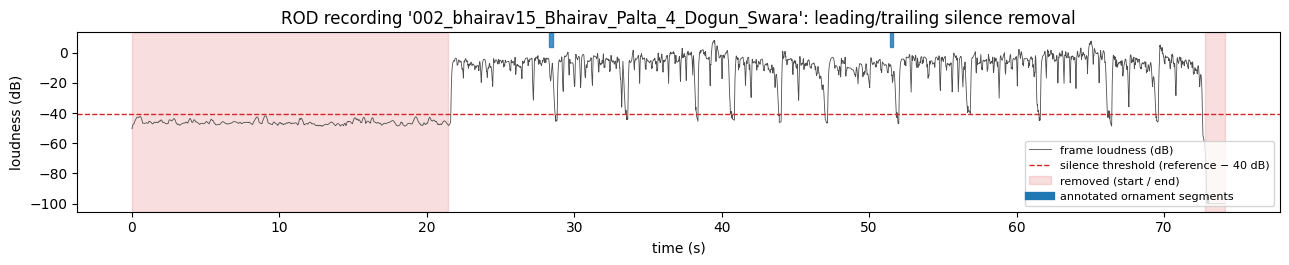

In [5]:
# ---- what the trimming does on an example recording ----
fig, axes = plt.subplots(len(RAW), 1, figsize=(13, 2.75 * len(RAW)), squeeze=False); axes = axes[:, 0]
for ax, name in zip(axes, RAW):
    t = max(RAW[name], key=lambda r: [x for x in D[name] if x['id'] == r['id']][0]['trim'][0])   # most leading silence
    tt = next(x for x in D[name] if x['id'] == t['id']); a, b, T = tt['trim']; fps = t['fps']
    e = loudness_db(t); time_s = np.arange(T) / fps
    ax.plot(time_s, e, lw=0.6, color='0.3', label='frame loudness (dB)')
    ax.axhline(tt['ref_db'] - SIL_DB, color='tab:red', ls='--', lw=1, label=f'silence threshold (reference − {SIL_DB:.0f} dB)')
    ax.axvspan(0, a / fps, color='tab:red', alpha=0.15, label='removed (start / end)')
    ax.axvspan(b / fps, T / fps, color='tab:red', alpha=0.15)
    for s, e_, l in t['segs']:
        if l: ax.axvspan(s, e_, ymin=0.92, ymax=1.0, color='tab:blue', alpha=0.8)
    ax.plot([], [], color='tab:blue', lw=6, label='annotated ornament segments')
    ax.set(title=f"{name} recording '{t['id']}': leading/trailing silence removal", xlabel='time (s)', ylabel='loudness (dB)')
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

## 4. Normalisation

Every constant-Q bin is standardised to zero mean and unit variance. The mean and standard deviation come from the **trimmed training recordings only**, and the same statistics are applied to validation and test. Nothing else is done to the features: no augmentation, no frequency masking, no extra features.

In [6]:
class SegData:
    def __init__(s, tracks):
        s.name, s.fps = tracks[0]['dataset'], float(tracks[0]['fps'])
        s.tracks = {sp: [t for t in tracks if t['split'] == sp] for sp in SPLITS}
        X = np.concatenate([t['x'] for t in s.tracks['train']]).astype(np.float64)
        s.mu, s.sd = X.mean(0).astype(np.float32), (X.std(0) + 1e-5).astype(np.float32)
        s.n_feat = X.shape[1]
        # (freq, time) per recording, kept on the CPU and copied to the GPU one recording at a time
        s.x = {t['id']: torch.from_numpy(((t['x'] - s.mu) / s.sd).T.astype(np.float16).copy()) for t in tracks}
        s.y = {t['id']: torch.from_numpy(t['y'].astype(np.int64)) for t in tracks}
        s.longest = {sp: max(ts, key=lambda t: len(t['y'])) for sp, ts in s.tracks.items()}

    def get(s, t):     # -> x: (1, 1, F, T) float32, y: (1, T)
        return s.x[t['id']].to(DEV, non_blocking=True).float()[None, None], s.y[t['id']].to(DEV)[None]

DATA = {name: SegData(D[name]) for name in D}
for name, d in DATA.items():
    xtr = torch.cat([d.x[t['id']].float() for t in d.tracks['train']], 1)
    print(f"{name}: train-normalised features mean {xtr.mean():.3f}, std {xtr.std():.3f} | longest recording per split (frames): "
          + ', '.join(f"{sp}={len(d.longest[sp]['y'])}" for sp in SPLITS))
del xtr

ROD: train-normalised features mean 0.000, std 1.000 | longest recording per split (frames): train=15363, val=9649, test=15370


## 5. Evaluation metrics

Predicted segments are the runs of a single ornament class in the per-frame labels produced by watershed decoding (section 11). Each predicted segment is matched one-to-one (greedy, by IoU) to a ground-truth segment **of the same class** with temporal IoU ≥ 0.5.

* **Precision** = matched / predicted segments, **Recall** = matched / ground-truth segments, **F1** = their harmonic mean. This segment F1 is the number used to choose models.
* **IoU**: frame-level IoU per ornament class, macro-averaged (`IoU_macro`); ornament-vs-none IoU (`IoU_orn`); mean IoU of the matched segments (`IoU_matched`).
* **Segment Jaccard** (`seg_jaccard`) = TP / (TP + FP + FN). (Called "segment-level accuracy" in version 1; it is not an accuracy, so it was renamed.) A segment counts as correct only if its class and its extent (IoU ≥ 0.5) are both right. Missed and spurious segments both count as errors.
* **Per-class**: segment-level P / R / F1 for each ornament class (plus that class's **frame-level** IoU, now named `frame_IoU` so it is not mistaken for a segment metric), and frame-level P / R / F1 / IoU for all classes (including `none`).

In [7]:
def runs(lab):
    lab = np.asarray(lab)
    if len(lab) == 0: return []
    ch = np.flatnonzero(np.diff(lab)) + 1
    st, en = np.r_[0, ch], np.r_[ch, len(lab)]
    return [(int(a), int(b), int(lab[a])) for a, b in zip(st, en) if lab[a] > 0]

def match(pred, gt, thr, class_aware=True):
    if not pred or not gt: return []
    P, G = np.array(pred, float), np.array(gt, float)
    inter = np.clip(np.minimum(P[:, None, 1], G[None, :, 1]) - np.maximum(P[:, None, 0], G[None, :, 0]), 0, None)
    union = np.maximum(P[:, None, 1], G[None, :, 1]) - np.minimum(P[:, None, 0], G[None, :, 0])
    iou = inter / np.maximum(union, 1e-9)
    if class_aware: iou = np.where(P[:, None, 2] == G[None, :, 2], iou, 0.0)
    ii, jj = np.nonzero(iou >= thr)
    used_p, used_g, pairs = set(), set(), []
    for k in np.argsort(-iou[ii, jj], kind='stable'):
        i, j = int(ii[k]), int(jj[k])
        if i not in used_p and j not in used_g:
            used_p.add(i); used_g.add(j); pairs.append((i, j, float(iou[i, j])))
    return pairs

def evaluate(labs, tracks, thr=0.5, tol=0.1):
    tp = tp_any = tp30 = n_pred = n_gt = n_bnd = 0
    ious, inter, union = [], np.zeros(NC), np.zeros(NC)
    i_orn = u_orn = corr = n_valid = 0
    c_tp, c_np, c_ng = np.zeros(NC), np.zeros(NC), np.zeros(NC)
    for t in tracks:
        lab, y, fps = labs[t['id']], t['y'], t['fps']
        valid = y != IGNORE
        pred = [(s / fps, e / fps, c) for s, e, c in runs(np.where(valid, lab, 0))]
        gt = [(s, e, C2I[l]) for s, e, l in t['segs'] if l is not None]
        pairs = match(pred, gt, thr)
        tp += len(pairs); n_pred += len(pred); n_gt += len(gt)
        tp_any += len(match(pred, gt, thr, class_aware=False)); tp30 += len(match(pred, gt, 0.3))
        ious += [p[2] for p in pairs]
        n_bnd += sum(abs(pred[i][0] - gt[j][0]) <= tol and abs(pred[i][1] - gt[j][1]) <= tol for i, j, _ in pairs)
        for i, j, _ in pairs: c_tp[gt[j][2]] += 1
        for p in pred: c_np[p[2]] += 1
        for g in gt: c_ng[g[2]] += 1
        lv, yv = lab[valid], y[valid]
        for c in range(1, NC):
            inter[c] += np.sum((lv == c) & (yv == c)); union[c] += np.sum((lv == c) | (yv == c))
        i_orn += np.sum((lv > 0) & (yv > 0)); u_orn += np.sum((lv > 0) | (yv > 0))
        corr += np.sum(lv == yv); n_valid += len(yv)
    f1 = lambda a, b: 2 * a * b / max(a + b, 1e-9)
    P, R = tp / max(n_pred, 1), tp / max(n_gt, 1)
    Pa, Ra = tp_any / max(n_pred, 1), tp_any / max(n_gt, 1)
    present = [c for c in range(1, NC) if c_ng[c] > 0]
    out = dict(P=P, R=R, F1=f1(P, R), F1_any=f1(Pa, Ra), F1_iou30=f1(tp30 / max(n_pred, 1), tp30 / max(n_gt, 1)),
               IoU_macro=float(np.mean([inter[c] / max(union[c], 1) for c in present])),
               IoU_orn=i_orn / max(u_orn, 1), IoU_matched=float(np.mean(ious)) if ious else 0.0,
               seg_jaccard=tp / max(n_pred + n_gt - tp, 1), boundary_acc=n_bnd / max(n_gt, 1),
               frame_acc=corr / max(n_valid, 1), n_pred=n_pred, n_gt=n_gt)
    per_class = {CLASSES[c]: dict(P=c_tp[c] / max(c_np[c], 1), R=c_tp[c] / c_ng[c],
                                  F1=f1(c_tp[c] / max(c_np[c], 1), c_tp[c] / c_ng[c]),
                                  frame_IoU=inter[c] / max(union[c], 1), n_gt=int(c_ng[c]), n_pred=int(c_np[c])) for c in present}
    return out, per_class

def frame_report(labs, tracks):
    cm = np.zeros((NC, NC), np.int64)
    for t in tracks:
        y = t['y']; v = y != IGNORE
        np.add.at(cm, (y[v], labs[t['id']][v]), 1)
    tp = np.diag(cm).astype(float); npred, ngt = cm.sum(0), cm.sum(1)
    P, R = tp / np.maximum(npred, 1), tp / np.maximum(ngt, 1)
    return pd.DataFrame(dict(precision=P, recall=R, F1=2 * P * R / np.maximum(P + R, 1e-9),
                             IoU=tp / np.maximum(npred + ngt - tp, 1), gt_frames=ngt, pred_frames=npred), index=CLASSES), cm

# self-test: K predicted exactly; H predicted as Me -> P = R = 0.5, class-agnostic F1 = 1, seg_jaccard = 1/3
_t = dict(id='t', fps=10.0, y=np.array([0, 1, 1, 1, 0, 0, 2, 2, 0, 0]), segs=[(0.1, 0.4, 'K'), (0.6, 0.8, 'H')])
_m, _ = evaluate({'t': np.array([0, 1, 1, 1, 0, 0, 3, 3, 3, 0])}, [_t])
assert _m['P'] == 0.5 and _m['R'] == 0.5 and _m['F1_any'] == 1.0 and abs(_m['seg_jaccard'] - 1 / 3) < 1e-9 and _m['IoU_macro'] == 0.5
print('metric self-test passed')

metric self-test passed


## 6. Model: Attention Residual U-Net

The CQT of a whole recording is treated as a one-channel image: frequency × time.

* **Residual blocks** (He et al., 2016; as in ResUNet, Zhang et al., 2018): every block of the encoder, bottleneck and decoder is `3×3 conv → BN → ReLU → 3×3 conv → BN`, **plus a shortcut** that adds the block's input to its output (a 1×1 convolution + BN when the number of channels changes), followed by ReLU. The shortcut lets the gradient bypass the convolutions, which makes deeper U-Nets (4–5 levels) easier to train.
* **Encoder**: residual block, then 2×2 max-pooling, at each level; channels `base → 2·base → …`. **Bottleneck**: one residual block with `base·2^levels` channels.
* **Decoder**: a 2×2 transposed convolution upsamples; the encoder features of the same level (the **skip connection**) first pass through an **attention gate**, then both are concatenated and go through a residual block.
* **Attention gate** (additive attention, Oktay et al., 2018, *Attention U-Net*): from the upsampled decoder features `g` (which carry coarse, long-range context) and the skip features `x` (fine detail), it computes a map α = sigmoid(ψ(ReLU(W_g·g + W_x·x))) with values between 0 and 1 for every time–frequency position, and passes `α · x` to the decoder. Regions that the coarse context marks as irrelevant (e.g. background between ornaments) are suppressed instead of being copied straight into the decoder. In this implementation the gate is applied after the upsampling, so `g` and `x` have the same resolution (a common simplification of the original, which down-samples `x` instead).
* **Output**: a convolution spanning the whole frequency axis gives 5 class scores per frame (as in versions 1 and 2). There is **no temporal module** (TCN / GRU) in this version.
* The input is zero-padded so frequency and time are multiples of 2^levels; the padding is cut off at the output.
* Optional dropout (a search setting) in the bottleneck and decoder blocks.
* `receptive_field()` measures the receptive field of a trained model directly (back-propagation from one output frame to the input).

In [8]:
class ResBlock(nn.Module):
    """Residual block: (3x3 conv -> BN -> ReLU -> 3x3 conv -> BN) + shortcut, then ReLU (and optional dropout)."""
    def __init__(s, ci, co, dropout=0.0):
        super().__init__()
        s.body = nn.Sequential(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                               nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co))
        s.short = nn.Identity() if ci == co else nn.Sequential(nn.Conv2d(ci, co, 1, bias=False), nn.BatchNorm2d(co))
        s.act = nn.ReLU(inplace=True)
        s.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
    def forward(s, x): return s.drop(s.act(s.body(x) + s.short(x)))

class AttentionGate(nn.Module):
    """Additive attention gate on a skip connection: alpha = sigmoid(psi(relu(Wg g + Wx x))), output alpha * x."""
    def __init__(s, cg, cx, ci):
        super().__init__()
        s.wg = nn.Sequential(nn.Conv2d(cg, ci, 1, bias=False), nn.BatchNorm2d(ci))
        s.wx = nn.Sequential(nn.Conv2d(cx, ci, 1, bias=False), nn.BatchNorm2d(ci))
        s.psi = nn.Sequential(nn.Conv2d(ci, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(s, g, x):
        a = s.psi(F.relu(s.wg(g) + s.wx(x)))                         # (B, 1, F, T), values in [0, 1]
        return x * a, a

class AttResUNet(nn.Module):
    def __init__(s, n_freq, n_cls=NC, base=16, levels=3, dropout=0.0):
        super().__init__()
        s.mult = 2 ** levels
        s.Fp = -(-n_freq // s.mult) * s.mult                         # padded frequency size
        chs = [base * 2 ** i for i in range(levels)]                  # e.g. 16, 32, 64
        s.enc, c = nn.ModuleList(), 1
        for co in chs:
            s.enc.append(ResBlock(c, co)); c = co
        s.pool = nn.MaxPool2d(2)
        s.bottleneck = ResBlock(c, base * 2 ** levels, dropout); c = base * 2 ** levels
        s.up, s.att, s.dec = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for co in reversed(chs):
            s.up.append(nn.ConvTranspose2d(c, co, 2, stride=2))
            s.att.append(AttentionGate(co, co, max(co // 2, 4)))
            s.dec.append(ResBlock(2 * co, co, dropout)); c = co
        s.head = nn.Conv2d(c, n_cls, kernel_size=(s.Fp, 1))          # whole frequency axis -> class scores per frame

    def forward(s, x, return_attention=False):                       # x: (B, 1, F, T) -> logits (B, n_cls, T)
        B, _, Fq, T = x.shape
        x = F.pad(x, (0, (-T) % s.mult, 0, s.Fp - Fq))
        skips = []
        for enc in s.enc:
            x = enc(x); skips.append(x); x = s.pool(x)
        x = s.bottleneck(x); maps = []
        for up, att, dec in zip(s.up, s.att, s.dec):
            g = up(x)
            skip, a = att(g, skips.pop()); maps.append(a[:, 0])
            x = dec(torch.cat([g, skip], 1))
        out = s.head(x)[:, :, 0, :T]
        return (out, maps) if return_attention else out              # maps: coarsest level first, finest last

def build_model(cfg, data):
    return AttResUNet(data.n_feat, NC, cfg['base'], cfg['levels'], cfg['dropout']).to(DEV)

def make_optimizer(cfg, model):
    if cfg['optim'] == 'adam':  return torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'adamw': return torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'sgd':   return torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    raise ValueError(cfg['optim'])

def receptive_field(model, data, tracks, max_frames=4000):
    """Measured temporal receptive field: which input frames influence the output at the centre frame."""
    t = max(tracks, key=lambda t: len(t['y'])); x, _ = data.get(t)
    x = x[..., :max_frames].clone().requires_grad_(True); T = x.shape[-1]; c = T // 2
    model.eval()
    with torch.enable_grad():
        model(x)[0, :, c].abs().sum().backward()
    g = x.grad[0, 0].abs().sum(0).cpu().numpy(); nz = np.flatnonzero(g > 0)
    cs = np.cumsum(g) / g.sum(); lo, hi = np.searchsorted(cs, 0.05), np.searchsorted(cs, 0.95)
    model.zero_grad(set_to_none=True)
    return dict(theoretical_s=(nz[-1] - nz[0] + 1) / data.fps, effective90_s=(hi - lo + 1) / data.fps,
                window_s=T / data.fps, reaches_window_edge=bool(nz[0] == 0 or nz[-1] == T - 1))

# default settings; every configuration of the search fills in these keys. gamma = 0 -> cross-entropy, > 0 -> focal loss
BASE = dict(lr=1e-3, optim='adam', wd=0.0, dropout=0.0, base=16, levels=3, sched='none', gamma=0.0)
for _lv in (3, 5):
    _m = build_model(dict(BASE, levels=_lv), DATA['ROD'])
    with torch.no_grad():
        _o, _maps = _m(torch.zeros(1, 1, DATA['ROD'].n_feat, 1000, device=DEV), return_attention=True)
    print(f"levels={_lv}: {sum(p.numel() for p in _m.parameters()) / 1e6:.3f} M parameters | input (1, 1, {DATA['ROD'].n_feat}, 1000) "
          f"-> output {tuple(_o.shape)} | attention maps {[tuple(a.shape) for a in _maps]}")
    del _m, _o, _maps
torch.cuda.empty_cache()

levels=3: 0.528 M parameters | input (1, 1, 216, 1000) -> output (1, 5, 1000) | attention maps [(1, 54, 250), (1, 108, 500), (1, 216, 1000)]
levels=5: 8.237 M parameters | input (1, 1, 216, 1000) -> output (1, 5, 1000) | attention maps [(1, 14, 64), (1, 28, 128), (1, 56, 256), (1, 112, 512), (1, 224, 1024)]


## 7. GPU memory check on the longest recording

Training uses one **entire** recording per step: no crops, no shortening. Before training, one full training step (forward pass, backward pass and optimiser update) is run on the **longest training recording**, and its peak GPU memory is compared with the free GPU memory.

On Windows the GPU driver can spill into **shared system memory (RAM)** when the GPU's own memory is full, instead of raising an out-of-memory error. This still gives correct results, but it is slower: on this laptop a base-32 U-Net step on the longest recording took 7.9 s, against 0.5 s for the base-16 model that fits in GPU memory. The extra work of the bigger model explains only about 4× of that gap.

* `ALLOW_SHARED_MEMORY = True` (used here): such configurations are trained anyway and are **flagged** as `uses_shared_memory` in the results, so their slower run times are visible.
* `ALLOW_SHARED_MEMORY = False`: they are reported as a memory error and not trained.

A real CUDA out-of-memory error is always reported, and that experiment is marked as failed. Recordings are never shortened.

In [9]:
MEM_SAFETY = 0.95
ALLOW_SHARED_MEMORY = True     # 24 GB system RAM: allow (slower) spill into shared memory, but flag it

def memory_check(cfg, data):
    gc.collect(); torch.cuda.empty_cache()
    free = torch.cuda.mem_get_info()[0]; r0 = torch.cuda.memory_reserved()
    torch.cuda.reset_peak_memory_stats()
    t = data.longest['train']; model = opt = None; err = None; peak = float('nan')
    try:
        model = build_model(cfg, data); opt = make_optimizer(cfg, model)
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        F.cross_entropy(logits.float(), y, ignore_index=IGNORE).backward(); opt.step(); torch.cuda.synchronize()
        peak = torch.cuda.max_memory_reserved() - r0
    except torch.OutOfMemoryError:
        err = 'CUDA out of memory during a full-recording training step'
    model = opt = x = y = logits = None; gc.collect(); torch.cuda.empty_cache()
    spills = err is None and peak > MEM_SAFETY * free
    msg = (f'needs {peak / 2**20:.0f} MiB but only {free / 2**20:.0f} MiB of GPU memory is free '
           f'-> spills into shared system memory (slower)') if spills else None
    ok = err is None and (not spills or ALLOW_SHARED_MEMORY)
    if err is None and not ok: err = msg
    return dict(ok=ok, uses_shared_memory=spills, peak_MiB=peak / 2**20, free_MiB=free / 2**20, frames=len(t['y']),
                seconds=len(t['y']) / data.fps, error=err, note=msg)

rows = []
for name, d in DATA.items():
    mc = memory_check(BASE, d); rows.append(dict(dataset=name, **mc))
display(pd.DataFrame(rows).set_index('dataset').round(1))
for r in rows:
    if not r['ok']:
        raise RuntimeError(f"MEMORY ISSUE ({r['dataset']}): the starting U-Net does not fit for the longest training recording "
                           f"({r['frames']} frames): {r['error']}. Recordings are NOT shortened and random crops are NOT used.")
for r in rows:
    print(f"{r['dataset']}: starting U-Net " + (f"WARNING - {r['note']}" if r['uses_shared_memory'] else 'fits in GPU memory')
          + f" for the longest training recording ({r['frames']} frames, {r['seconds']:.0f} s)")

,ok,uses_shared_memory,peak_MiB,free_MiB,frames,seconds,error,note
dataset,,,,,,,,
ROD,True,False,4470.0,14758.8,15363,153.6,None,None


ROD: starting U-Net fits in GPU memory for the longest training recording (15363 frames, 154 s)


## 8. Training

* **Loss** (search setting `gamma`), no class weights:
  * `gamma = 0`: ordinary multi-class **cross-entropy** over the 5 classes, as in version 2: $\;L = -\log p_t$, where $p_t$ is the predicted probability of the true class of a frame.
  * `gamma = 2, 3, 4`: **focal loss** (Lin et al., 2017): $\;L = -(1-p_t)^{\gamma}\log p_t$. Frames the model already classifies confidently ($p_t$ close to 1, mostly the many easy `none` frames) are down-weighted, so training concentrates on hard frames (ornament boundaries, rare classes, confusable ornaments). A larger γ down-weights easy frames more strongly.
  * Ignored frames (label `-100`) are excluded; the loss is averaged over the remaining frames of the recording. The **validation loss** that is reported is always plain cross-entropy, so it is comparable between losses.
* **One full recording per step**, in a random order each epoch. No crops, no augmentation.
* **Learning-rate schedule** (search setting `sched`): constant, or cosine decay over `max_epochs`.
* **Checkpoint selection**: the weights from the epoch that ends the best **3-epoch moving average** of validation F1 are kept, and early stopping uses the same moving average. That moving-average value is the **score** used to compare runs.
* Mixed precision (bf16), gradients clipped at norm 1.
* Every experiment is saved to `rod_koopman/unet_seg_v3/runs/` (`.json` with settings, curves, metrics and status; `.pt` with the kept weights; `_epochs.npz` with the predicted class probabilities on the first 25 s of two fixed validation recordings **after every epoch**, used for the epoch-wise images in section 12). A saved experiment is reused only if it was made with the same code version, budget, class list and split.
* **Validation F1 after every epoch uses watershed decoding**: the watershed (section 11) is tuned on the validation recordings after each epoch (80 combinations, a few seconds) and the segment F1 with the best setting is that epoch's validation F1. Checkpointing (3-epoch average), early stopping and the search all use this value. The parameters of every epoch are stored in the run history.


In [10]:
# ---- watershed decoding (explained in section 11): gives the validation F1 after every epoch ----
from scipy.ndimage import gaussian_filter1d
import itertools

@torch.no_grad()
def predict_proba(model, data, tracks, with_loss=False):
    """Per-frame class probabilities, shape (NC, T), for every recording (+ frame-averaged cross-entropy if with_loss)."""
    model.eval(); out, loss_sum, n = {}, 0.0, 0
    for t in tracks:
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        logits = logits.float()
        if with_loss:
            loss_sum += float(F.cross_entropy(logits, y, ignore_index=IGNORE, reduction='sum')); n += int((y != IGNORE).sum())
        out[t['id']] = torch.softmax(logits[0], 0).cpu().numpy()
    return (out, loss_sum / max(n, 1)) if with_loss else out

def smooth_probs(P, fps, sigma_s):
    return gaussian_filter1d(P, sigma_s * fps, axis=1, mode='nearest') if sigma_s > 0 else P

def _lead_true(m):   # number of leading True values of a boolean array
    return len(m) if m.all() else int(np.argmin(m))

def watershed_decode(P, fps, t_high=0.7, t_low=0.4, min_seed_s=0.05, sigma_s=0.0):
    """1-D marker-controlled watershed. P: (NC, T) class probabilities -> per-frame labels (0 = none)."""
    P = smooth_probs(P, fps, sigma_s); T = P.shape[1]
    p_orn = 1.0 - P[0]                                       # probability that the frame is any ornament
    cls, p_cls = P[1:].argmax(0) + 1, P[1:].max(0)
    # 1) seeds: runs of one ornament class with probability >= t_high, at least min_seed_s long
    min_len = max(1, int(round(min_seed_s * fps)))
    seeds = [(a, b) for a, b, _ in runs(np.where(p_cls >= t_high, cls, 0)) if b - a >= min_len]
    lab = np.zeros(T, np.int64)
    if not seeds: return lab
    # 2) flooding: each seed grows while p_orn >= t_low; two floods that meet are split at the least
    #    ornament-like frame between them (the watershed line)
    mask = p_orn >= t_low
    L, R = [0] * len(seeds), [0] * len(seeds)
    L[0] = seeds[0][0] - _lead_true(mask[:seeds[0][0]][::-1])
    R[-1] = seeds[-1][1] + _lead_true(mask[seeds[-1][1]:])
    for k in range(len(seeds) - 1):
        b, a2 = seeds[k][1], seeds[k + 1][0]
        gap = mask[b:a2]
        if gap.all():
            R[k] = L[k + 1] = b + int(np.argmin(p_orn[b:a2])) + 1 if a2 > b else b
        else:
            R[k], L[k + 1] = b + _lead_true(gap), a2 - _lead_true(gap[::-1])
    # 3) one class per region: the ornament class with the highest mean probability over the region
    for l, r in zip(L, R):
        lab[l:r] = int(P[1:, l:r].mean(1).argmax()) + 1
    return lab          # touching regions of the same class form one segment (runs() merges them)

def ws_decode_all(probs, tracks, **p): return {t['id']: watershed_decode(probs[t['id']], t['fps'], **p) for t in tracks}

def seg_f1(labs, tracks):   # segment F1 only (IoU >= 0.5, same class), fast enough for the parameter grid
    tp = npred = ngt = 0
    for t in tracks:
        lab, fps = np.where(t['y'] != IGNORE, labs[t['id']], 0), t['fps']
        pred = [(s / fps, e / fps, c) for s, e, c in runs(lab)]
        gt = [(s, e, C2I[l]) for s, e, l in t['segs'] if l is not None]
        tp += len(match(pred, gt, 0.5)); npred += len(pred); ngt += len(gt)
    P, R = tp / max(npred, 1), tp / max(ngt, 1)
    return 2 * P * R / max(P + R, 1e-9)

WS_GRID = dict(t_high=[0.5, 0.6, 0.7, 0.8, 0.9], t_low=[0.2, 0.3, 0.4, 0.5], sigma_s=[0.0, 0.05, 0.1, 0.2])
# min_seed_s is not tuned: it is the duration of the shortest ornament segment in the TRAINING labels
MIN_SEED_S = {ds: float(min(e - s for t in DATA[ds].tracks['train'] for s, e, l in t['segs'] if l)) for ds in DATA}
for ds in DATA:
    print(f"{ds}: min_seed_s = shortest training ornament segment = {MIN_SEED_S[ds]:.3f} s ({MIN_SEED_S[ds] * DATA[ds].fps:.1f} frames)")

def tune_watershed(probs, tracks, min_seed_s):
    rows = []
    for sg in WS_GRID['sigma_s']:
        sm = {t['id']: smooth_probs(probs[t['id']], t['fps'], sg) for t in tracks}       # smoothed once per sigma
        for th, tl in itertools.product(WS_GRID['t_high'], WS_GRID['t_low']):
            if tl > th: continue
            rows.append(dict(t_high=th, t_low=tl, min_seed_s=min_seed_s, sigma_s=sg,
                             val_F1=seg_f1(ws_decode_all(sm, tracks, t_high=th, t_low=tl, min_seed_s=min_seed_s), tracks)))
    grid = pd.DataFrame(rows).sort_values('val_F1', ascending=False, kind='stable').reset_index(drop=True)
    return {k: float(grid.loc[0, k]) for k in ('t_high', 't_low', 'min_seed_s', 'sigma_s')}, grid

# self-test: an H ornament whose argmax flips to K for one frame, a touching Me ornament, and an unsure one-frame K blip
_P = np.zeros((NC, 40)); _P[0] = 1.0
def _set(f, c, p, c2=None, p2=0.0):
    _P[:, f] = 0.0; _P[c, f] = p
    if c2: _P[c2, f] = p2
    _P[0, f] = 1.0 - p - p2
for _f in range(5, 15): _set(_f, C2I['H'], 0.9)
_set(10, C2I['K'], 0.5, C2I['H'], 0.45)
for _f in range(15, 22): _set(_f, C2I['Me'], 0.8)
_set(26, C2I['K'], 0.6)
assert runs(_P.argmax(0)) == [(5, 10, C2I['H']), (10, 11, C2I['K']), (11, 15, C2I['H']), (15, 22, C2I['Me']), (26, 27, C2I['K'])]
assert runs(watershed_decode(_P, 100.0, t_high=0.7, t_low=0.4, min_seed_s=0.02)) == [(5, 15, C2I['H']), (15, 22, C2I['Me'])]
print('watershed self-test passed: argmax gives 5 segments, watershed gives the 2 real ones')

@torch.no_grad()
def predict(model, data, tracks):
    # full-recording inference -> per-frame most likely class, and the frame-averaged cross-entropy (used for the test CE only)
    model.eval(); labs, loss_sum, n = {}, 0.0, 0
    for t in tracks:
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        logits = logits.float()
        loss_sum += float(F.cross_entropy(logits, y, ignore_index=IGNORE, reduction='sum')); n += int((y != IGNORE).sum())
        labs[t['id']] = logits[0].argmax(0).cpu().numpy()
    return labs, loss_sum / max(n, 1)

def seg_loss(logits, y, gamma=0.0):
    """gamma = 0: multi-class cross-entropy. gamma > 0: focal loss -(1 - p_t)^gamma * log(p_t). No class weights.
    Ignored frames are excluded; the result is the mean over the valid frames."""
    ce = F.cross_entropy(logits, y, ignore_index=IGNORE, reduction='none')     # (B, T), 0 at ignored frames
    valid = y != IGNORE
    if gamma > 0:
        ce = (1 - torch.exp(-ce)).pow(gamma) * ce                                # exp(-ce) = p_t
    return ce[valid].sum() / valid.sum().clamp(min=1)

# self-test: gamma = 0 equals PyTorch's cross-entropy; focal loss is smaller and shrinks as gamma grows
_lg, _y = torch.randn(1, NC, 50), torch.randint(0, NC, (1, 50)); _y[0, :5] = IGNORE
assert torch.allclose(seg_loss(_lg, _y, 0.0), F.cross_entropy(_lg, _y, ignore_index=IGNORE))
assert seg_loss(_lg, _y, 4.0) < seg_loss(_lg, _y, 3.0) < seg_loss(_lg, _y, 2.0) < seg_loss(_lg, _y, 0.0)
print('loss self-test passed')

def loss_name(gamma): return 'CE' if gamma == 0 else f'focal_g{gamma:g}'

# ---- predictions on two fixed validation recordings are stored after every epoch (for the epoch-wise images) ----
EPOCH_EXAMPLE_S = 25.0          # seconds kept from the start of each example recording
def epoch_examples(data, k=2):  # the validation recordings with the most ornaments per second
    return sorted(data.tracks['val'], key=lambda t: -sum(1 for s in t['segs'] if s[2]) / max(t['dur'], 1))[:k]

@torch.no_grad()
def example_probs(model, data):
    model.eval(); out = []
    for t in epoch_examples(data):
        x, _ = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            p = torch.softmax(model(x).float()[0], 0)
        out.append(p[:, :int(EPOCH_EXAMPLE_S * data.fps)].cpu().numpy().astype(np.float16))
    return out

MA_WINDOW = 3          # epochs in the moving average of validation F1 used for checkpointing and comparison
CODE_VERSION = 'v3-ws' # stored in every saved experiment; a saved result from other code is not reused
import hashlib
def split_id(ds):      # fingerprint of the train / val / test recording lists
    return hashlib.md5(json.dumps(SPLIT_LISTS[ds], sort_keys=True).encode()).hexdigest()[:12]

import threading
_INIT_LOCK = threading.Lock()   # the CPU random generator is shared by the GPU worker threads

def train_run(cfg, data, max_epochs, patience, seed=SEED, log_every=5):
    with _INIT_LOCK:              # seeding + weight initialisation one thread at a time -> reproducible initial weights
        seed_all(seed); rng = np.random.default_rng(seed)
        model = build_model(cfg, data); opt = make_optimizer(cfg, model)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs) if cfg.get('sched', 'none') == 'cosine' else None
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE == torch.float16)
    train = data.tracks['train']
    hist, best, best_ep, best_val, best_state, bad, status, t0 = [], -1.0, 0, None, None, 0, 'ok', time.time()
    best_ws = None                    # watershed parameters of the kept epoch
    ep_probs = []                     # class probabilities on the example recordings after every epoch
    torch.cuda.reset_peak_memory_stats()
    for ep in range(1, max_epochs + 1):
        model.train(); ls, n = 0.0, 0
        for i in rng.permutation(len(train)):
            x, y = data.get(train[i])
            with torch.autocast('cuda', dtype=AMP_DTYPE):
                logits = model(x)
            loss = seg_loss(logits.float(), y, cfg.get('gamma', 0.0))
            if not torch.isfinite(loss.detach()):
                status = 'failed: non-finite training loss'; break
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            k = int((y != IGNORE).sum()); ls += loss.item() * k; n += k
        if status != 'ok':
            print(f'    epoch {ep}: {status} - run stopped'); break
        if sched is not None: sched.step()
        vt = data.tracks['val']; probs, vloss = predict_proba(model, data, vt, with_loss=True)
        wp, _ = tune_watershed(probs, vt, MIN_SEED_S[data.name])      # watershed tuned on validation for this epoch
        labs = ws_decode_all(probs, vt, **wp); del probs
        ep_probs.append(example_probs(model, data))
        m, _ = evaluate(labs, data.tracks['val'])
        hist.append(dict(epoch=ep, train_loss=ls / n, val_loss=vloss, val_F1=m['F1'], val_IoU=m['IoU_macro'],
                         val_seg_jaccard=m['seg_jaccard'], val_frame_acc=m['frame_acc'], lr=opt.param_groups[0]['lr'], sec=time.time() - t0,
                         ws_t_high=wp['t_high'], ws_t_low=wp['t_low'], ws_sigma_s=wp['sigma_s']))
        ma = float(np.mean([h['val_F1'] for h in hist[-MA_WINDOW:]])); hist[-1]['val_F1_ma'] = ma
        if ma > best:
            best, best_ep, best_val, bad, best_ws = ma, ep, m, 0, dict(wp, min_seed_s=MIN_SEED_S[data.name])
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % log_every == 0 or ep == 1 or bad >= patience or ep == max_epochs:
            h = hist[-1]
            print(f"    [GPU{torch.cuda.current_device()}] ep {ep:3d} | train loss {h['train_loss']:.3f} | val CE {h['val_loss']:.3f} | val F1 (watershed) {h['val_F1']:.3f} "
                  f"(3-ep avg {ma:.3f}) | best avg {best:.3f} @ep{best_ep} | {h['sec'] / 60:.1f} min", flush=True)
        if bad >= patience: break
    peak = torch.cuda.max_memory_allocated() / 2**20
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    if best_state is None and status == 'ok': status = 'failed: no completed epoch'
    ok = best_state is not None
    return dict(status=status, best_epoch=best_ep, best_val_F1_ma=best if ok else float('nan'),
                best_val_F1=best_val['F1'] if ok else float('nan'), best_val=best_val, ws_params=best_ws, hist=hist, epochs_run=len(hist),
                minutes=(time.time() - t0) / 60, train_peak_MiB=peak), best_state, ep_probs

def tag_of(ds, cfg, seed=SEED):
    c = {**BASE, **cfg}
    return (f"{ds}_attres_lr{c['lr']:.2g}_{c['optim']}_wd{c['wd']:g}_do{c['dropout']:g}_b{c['base']}_L{c['levels']}"
            f"_{c['sched']}_{loss_name(c['gamma'])}_s{seed}")

def run_experiment(ds, cfg, seed=SEED):
    cfg = {**BASE, **cfg}; data, tag = DATA[ds], tag_of(ds, cfg, seed); jf = RUNS / f'{tag}.json'
    if jf.exists():
        r = json.loads(jf.read_text())
        if (r.get('code_version') == CODE_VERSION and r.get('budget') == BUDGET[ds] and r.get('classes') == CLASSES
                and r.get('split_id') == split_id(ds)):
            print(f"  [saved result reused] {tag}: {r['status']} | val F1 3-ep avg {r['best_val_F1_ma']:.3f}"); return r
        print(f'  [saved result NOT reused: made with different code, budget, classes or split] {tag}')
    print(f'  [GPU{torch.cuda.current_device()}] training {tag}', flush=True)
    r = dict(tag=tag, dataset=ds, seed=seed, code_version=CODE_VERSION, budget=BUDGET[ds], classes=CLASSES, split_id=split_id(ds), **cfg)
    mc = memory_check(cfg, data)
    r.update(mem_peak_MiB=mc['peak_MiB'], mem_free_MiB=mc['free_MiB'], uses_shared_memory=mc['uses_shared_memory'])
    if mc['ok'] and mc['uses_shared_memory']:
        print(f"    NOTE: {mc['note']} - training anyway (ALLOW_SHARED_MEMORY=True)")
    if not mc['ok']:
        r.update(status='memory error', error=mc['error'], best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
        print(f"    MEMORY ERROR: {mc['error']} - this experiment was NOT trained (recordings are not shortened)")
    else:
        try:
            info, state, ep_probs = train_run(cfg, data, seed=seed, **BUDGET[ds])
            r.update(info, n_params=sum(v.numel() for k, v in state.items() if 'running' not in k and 'num_batches' not in k) if state else None)
            if state is not None:
                torch.save(dict(cfg=cfg, seed=seed, state=state, mu=data.mu, sd=data.sd, dataset=ds, classes=CLASSES), RUNS / f'{tag}.pt')
                np.savez_compressed(RUNS / f'{tag}_epochs.npz', ids=np.array([t['id'] for t in epoch_examples(data)]),
                                    **{f'probs{i}': np.stack([e[i] for e in ep_probs]) for i in range(len(ep_probs[0]))})
        except torch.OutOfMemoryError as e:
            r.update(status='memory error', error=f'CUDA out of memory during training: {e}', best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
            print('    MEMORY ERROR during training:', e)
        except Exception as e:
            r.update(status='failed', error=repr(e), best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
            print('    EXPERIMENT FAILED:', repr(e))
        gc.collect(); torch.cuda.empty_cache()
    if r['status'] != 'ok': r.setdefault('error', r['status'])
    jf.write_text(json.dumps(r, indent=1, default=float))
    return r

def load_model(tag):
    ck = torch.load(RUNS / f'{tag}.pt', map_location='cpu', weights_only=False)
    m = build_model(ck['cfg'], DATA[ck['dataset']]); m.load_state_dict(ck['state']); return m.eval()

ROD: min_seed_s = shortest training ornament segment = 0.104 s (10.4 frames)
watershed self-test passed: argmax gives 5 segments, watershed gives the 2 real ones
loss self-test passed


## 9. Hyperparameter search: configurations × losses (validation only)

* **8 configurations**: the version-2 selected settings (lr 4e-4, Adam, weight decay 1e-5, dropout 0.3, base 12, 5 levels, cosine schedule; its TCN head is not used here) plus 7 drawn at random from the space below.
* Every configuration is trained with **all 4 losses**: cross-entropy and focal loss with γ = 2, 3, 4. So each loss is tried on exactly the same configurations, and the losses can be compared configuration by configuration (32 runs).
* **One seed** (`SEED`) per run; there is no seed-confirmation phase in this version.
* For **each loss** the configuration with the best score (best 3-epoch average of the **watershed** validation F1) is kept; the overall selected model is the best of these four. The test set is never looked at here.

| setting | values |
|---|---|
| `lr` | log-uniform between 1e-4 and 3e-3 |
| `optim` | Adam, AdamW |
| `wd` | 0, 1e-5, 1e-4, 1e-3, 1e-2 |
| `dropout` | 0, 0.1, 0.2, 0.3, 0.4 |
| `base` (channels base → 2·base → …) | 12, 16 |
| `levels` | 3, 4, 5 |
| `sched` | constant, cosine |
| `gamma` (loss) | 0 (cross-entropy), 2, 3, 4 (focal loss): every configuration gets all four |

Budget: up to 50 epochs, stopping when the 3-epoch average of validation F1 hasn't improved for 10 epochs. Expect roughly 15–20 minutes per run, i.e. about 9 hours for the 32 runs on the laptop GPU. Runs are ordered configuration by configuration (all 4 losses of one configuration before the next), so an interrupted search still gives complete loss comparisons; re-running the cell reuses every finished run.

In [11]:
BUDGET = {'ROD': dict(max_epochs=50, patience=10)}
N_CONFIGS = 8                       # configurations (anchor included); each one is trained with every loss
GAMMAS = [0.0, 2.0, 3.0, 4.0]       # 0 = cross-entropy, >0 = focal loss
SEARCH_SEED = 7                     # makes the list of random configurations reproducible
ANCHOR = dict(lr=4e-4, optim='adam', wd=1e-5, dropout=0.3, base=12, levels=5, sched='cosine')   # version-2 selected settings
LOSSES = [loss_name(g) for g in GAMMAS]

if SMOKE:   # quick end-to-end test of the code only
    BUDGET = {'ROD': dict(max_epochs=2, patience=1)}; N_CONFIGS = 2

def sample_cfg(rng):
    c = dict(lr=float(f'{10 ** rng.uniform(-4, np.log10(3e-3)):.2g}'), optim=str(rng.choice(['adam', 'adamw'])),
             wd=float(rng.choice([0.0, 1e-5, 1e-4, 1e-3, 1e-2])), dropout=float(rng.choice([0.0, 0.1, 0.2, 0.3, 0.4])),
             base=int(rng.choice([12, 16])), levels=int(rng.choice([3, 4, 5])), sched=str(rng.choice(['none', 'cosine'])))
    return {**BASE, **c}

def cfg_key(cfg):   # identifies a configuration independently of the loss and the seed
    c = {**BASE, **cfg}
    return f"lr{c['lr']:.2g}_{c['optim']}_wd{c['wd']:g}_do{c['dropout']:g}_b{c['base']}_L{c['levels']}_{c['sched']}"

HP = ['lr', 'optim', 'wd', 'dropout', 'base', 'levels', 'sched']

import queue, threading

def search(ds):
    rng = np.random.default_rng(SEARCH_SEED)
    cfgs, seen = [], set()
    for c in [{**BASE, **ANCHOR}] + [sample_cfg(rng) for _ in range(20 * N_CONFIGS)]:
        if cfg_key(c) not in seen: seen.add(cfg_key(c)); cfgs.append(c)
        if len(cfgs) == N_CONFIGS: break
    rows, t0, n = [], time.time(), len(cfgs) * len(GAMMAS)
    jobs = [(i, j, c, g) for i, c in enumerate(cfgs) for j, g in enumerate(GAMMAS)]
    # biggest models first, so the GPUs finish at about the same time; every GPU takes the next waiting run
    q = queue.Queue()
    for k in sorted(range(n), key=lambda k: -(jobs[k][2]['levels'] * 100 + jobs[k][2]['base'])): q.put(k)
    done = {}

    def worker(gpu):
        torch.cuda.set_device(gpu)
        while True:
            try: k = q.get_nowait()
            except queue.Empty: return
            i, j, c, g = jobs[k]
            print(f'\n=== [GPU{gpu}] {ds} | run {k + 1}/{n} | configuration {i + 1}/{len(cfgs)}: {cfg_key(c)} | loss {loss_name(g)}', flush=True)
            try:
                done[k] = run_experiment(ds, dict(c, gamma=g), SEED)
            except Exception as e:
                print(f'    [GPU{gpu}] EXPERIMENT FAILED:', repr(e), flush=True)
                done[k] = dict(tag=tag_of(ds, dict(c, gamma=g)), **c, gamma=g, status='failed', error=repr(e),
                               best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)

    print(f'{ds}: {n} runs on {N_GPU} GPU(s) in parallel')
    threads = [threading.Thread(target=worker, args=(gpu,)) for gpu in range(N_GPU)]
    for th in threads: th.start()
    for th in threads: th.join()
    torch.cuda.set_device(0)
    for k, (i, j, c, g) in enumerate(jobs):
            r = done[k]
            HIST[r['tag']] = r.get('hist', []); bv = r.get('best_val') or {}
            rows.append({**{k: r.get(k) for k in ('tag', *HP, 'gamma', 'status', 'best_val_F1_ma', 'best_val_F1', 'best_epoch',
                                                  'epochs_run', 'minutes', 'n_params', 'mem_peak_MiB', 'uses_shared_memory', 'error')},
                         'dataset': ds, 'config': cfg_key(c), 'anchor': i == 0, 'loss': loss_name(g),
                         'val_P': bv.get('P'), 'val_R': bv.get('R'), 'val_IoU': bv.get('IoU_macro'), 'val_seg_jaccard': bv.get('seg_jaccard'),
                         'ws_params': r.get('ws_params')})
    res = pd.DataFrame(rows); ok = res[res['status'] == 'ok']
    best_per_loss = {}
    for l in LOSSES:
        sub = ok[ok['loss'] == l]
        if len(sub):
            r = sub.loc[sub['best_val_F1_ma'].idxmax()]
            best_per_loss[l] = dict(tag=r['tag'], key=r['config'], cfg={**{k: r[k] for k in HP}, 'gamma': float(r['gamma'])},
                                    score=float(r['best_val_F1_ma']), F1=float(r['best_val_F1']), ws_params=r['ws_params'])
    sel_loss = max(best_per_loss, key=lambda l: best_per_loss[l]['score'])
    sel = dict(loss=sel_loss, **best_per_loss[sel_loss])
    res.to_csv(OUT / f'search_results_{ds}.csv', index=False)
    print(f"\n{ds} search finished in {(time.time() - t0) / 60:.1f} min | selected {sel['key']} with {sel_loss} (score {sel['score']:.3f})")
    return res, best_per_loss, sel

RES, BEST_PER_LOSS, SELECTED, HIST = {}, {}, {}, {}
RES['ROD'], BEST_PER_LOSS['ROD'], SELECTED['ROD'] = search('ROD')

ROD: 32 runs on 2 GPU(s) in parallel

=== [GPU0] ROD | run 5/32 | configuration 2/8: lr0.00084_adamw_wd0.01_do0.2_b16_L5_none | loss CE
  [GPU0] training ROD_attres_lr0.00084_adamw_wd0.01_do0.2_b16_L5_none_CE_s2035

=== [GPU1] ROD | run 6/32 | configuration 2/8: lr0.00084_adamw_wd0.01_do0.2_b16_L5_none | loss focal_g2
  [GPU1] training ROD_attres_lr0.00084_adamw_wd0.01_do0.2_b16_L5_none_focal_g2_s2035
    [GPU0] ep   1 | train loss 1.062 | val CE 0.938 | val F1 (watershed) 0.084 (3-ep avg 0.084) | best avg 0.084 @ep1 | 1.0 min
    [GPU1] ep   1 | train loss 0.644 | val CE 0.916 | val F1 (watershed) 0.123 (3-ep avg 0.123) | best avg 0.123 @ep1 | 1.0 min
    [GPU1] ep   5 | train loss 0.357 | val CE 0.822 | val F1 (watershed) 0.311 (3-ep avg 0.191) | best avg 0.191 @ep5 | 2.5 min
    [GPU0] ep   5 | train loss 0.717 | val CE 0.716 | val F1 (watershed) 0.324 (3-ep avg 0.276) | best avg 0.276 @ep5 | 2.6 min
    [GPU1] ep  10 | train loss 0.224 | val CE 0.537 | val F1 (watershed) 0.466 (3-e

In [12]:
# ---- all experiments, the configuration x loss table, and the best model per loss ----
cols = ['config', 'loss', 'anchor', 'status', 'best_val_F1_ma', 'best_val_F1', 'val_P', 'val_R', 'val_IoU', 'val_seg_jaccard',
        'best_epoch', 'epochs_run', 'minutes', 'n_params', 'uses_shared_memory']
for ds in RES:
    res = RES[ds]; ok = res[res['status'] == 'ok']
    print(f'{ds}: every experiment (validation; score = best 3-epoch average of validation F1)')
    display(res[cols].sort_values('best_val_F1_ma', ascending=False).round(4))
    print(f'{ds}: score of every configuration (rows) under every loss (columns)')
    piv = ok.pivot_table(index='config', columns='loss', values='best_val_F1_ma')[[l for l in LOSSES if l in set(ok['loss'])]]
    display(piv.round(3))
    comp = pd.DataFrame({l: dict(mean_score=piv[l].mean(), median_score=piv[l].median(), best_score=piv[l].max(),
                                 configs_where_best=int((piv.idxmax(axis=1) == l).sum()),
                                 mean_diff_vs_CE=(piv[l] - piv['CE']).mean() if 'CE' in piv else np.nan) for l in piv.columns}).T
    print(f'{ds}: loss comparison over the same configurations'); display(comp.round(3))
    print(f'{ds}: best configuration for each loss (chosen on validation)')
    display(pd.DataFrame(BEST_PER_LOSS[ds]).T[['key', 'score', 'F1']])
    s = SELECTED[ds]
    print(f"SELECTED {ds}: {s['key']} with {s['loss']} | score {s['score']:.3f}")
    for _, r in res[res['status'] != 'ok'].iterrows():
        print(f"  FAILED EXPERIMENT {r['tag']}: {r['status']} - {r['error']}")
pd.concat(RES.values()).to_csv(OUT / 'search_results_all.csv', index=False)
json.dump(dict(selected=SELECTED, best_per_loss=BEST_PER_LOSS), open(OUT / 'selected_models.json', 'w'), indent=1, default=float)

ROD: every experiment (validation; score = best 3-epoch average of validation F1)


,config,loss,anchor,status,best_val_F1_ma,best_val_F1,val_P,val_R,val_IoU,val_seg_jaccard,best_epoch,epochs_run,minutes,n_params,uses_shared_memory
0,lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine,CE,True,ok,0.7317,0.7436,0.7527,0.7346,0.6219,0.5918,43,50,19.4851,4638722,False
16,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,CE,False,ok,0.7145,0.7001,0.7088,0.6917,0.6042,0.5386,28,38,14.9894,2071097,False
17,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,focal_g2,False,ok,0.7143,0.7125,0.7471,0.6810,0.6016,0.5534,29,39,15.6840,2071097,False
5,lr0.00084_adamw_wd0.01_do0.2_b16_L5_none,focal_g2,False,ok,0.7142,0.7118,0.7186,0.7051,0.6029,0.5525,28,38,15.6394,8236988,False
31,lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine,focal_g4,False,ok,0.7058,0.7173,0.7544,0.6836,0.5977,0.5592,39,49,18.4292,4638722,False
18,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,focal_g3,False,ok,0.7057,0.7174,0.7716,0.6702,0.5958,0.5593,27,37,13.9565,2071097,False
28,lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine,CE,False,ok,0.6993,0.6979,0.7188,0.6783,0.6227,0.5360,33,43,16.1777,4638722,False
2,lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine,focal_g3,True,ok,0.6970,0.6667,0.7666,0.5898,0.5718,0.5000,34,44,16.1759,4638722,False
4,lr0.00084_adamw_wd0.01_do0.2_b16_L5_none,CE,False,ok,0.6952,0.7060,0.7426,0.6729,0.5903,0.5457,32,42,17.7466,8236988,False
19,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,focal_g4,False,ok,0.6925,0.6825,0.7135,0.6542,0.6001,0.5180,37,47,18.0713,2071097,False


ROD: score of every configuration (rows) under every loss (columns)


loss,CE,focal_g2,focal_g3,focal_g4
config,,,,
lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine,0.699,0.688,0.686,0.706
lr0.00021_adamw_wd0_do0.4_b16_L3_none,0.650,0.661,0.636,0.625
lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,0.715,0.714,0.706,0.693
lr0.00028_adam_wd0.01_do0.4_b12_L4_cosine,0.650,0.619,0.616,0.565
lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine,0.732,0.679,0.697,0.642
lr0.00084_adamw_wd0.01_do0.2_b16_L5_none,0.695,0.714,0.662,0.641
lr0.0015_adam_wd0.0001_do0.4_b12_L4_none,0.656,0.625,0.565,0.582
lr0.003_adamw_wd0.001_do0.3_b16_L4_cosine,0.659,0.669,0.685,0.631


ROD: loss comparison over the same configurations


,mean_score,median_score,best_score,configs_where_best,mean_diff_vs_CE
CE,0.682,0.677,0.732,4.0,0.000
focal_g2,0.671,0.674,0.714,2.0,-0.011
focal_g3,0.657,0.673,0.706,1.0,-0.025
focal_g4,0.635,0.636,0.706,1.0,-0.047


ROD: best configuration for each loss (chosen on validation)


,key,score,F1
CE,lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine,0.731668,0.743555
focal_g2,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,0.714258,0.712482
focal_g3,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,0.705737,0.71736
focal_g4,lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine,0.705767,0.7173


SELECTED ROD: lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine with CE | score 0.732


## 10. Plots of the search

1. Validation F1 (3-epoch average) and validation cross-entropy over the epochs, for every run, coloured by loss.
2. Loss comparison: the score of every configuration under each loss (one line per configuration).
3. Score against each hyperparameter (one dot per run, coloured by loss).

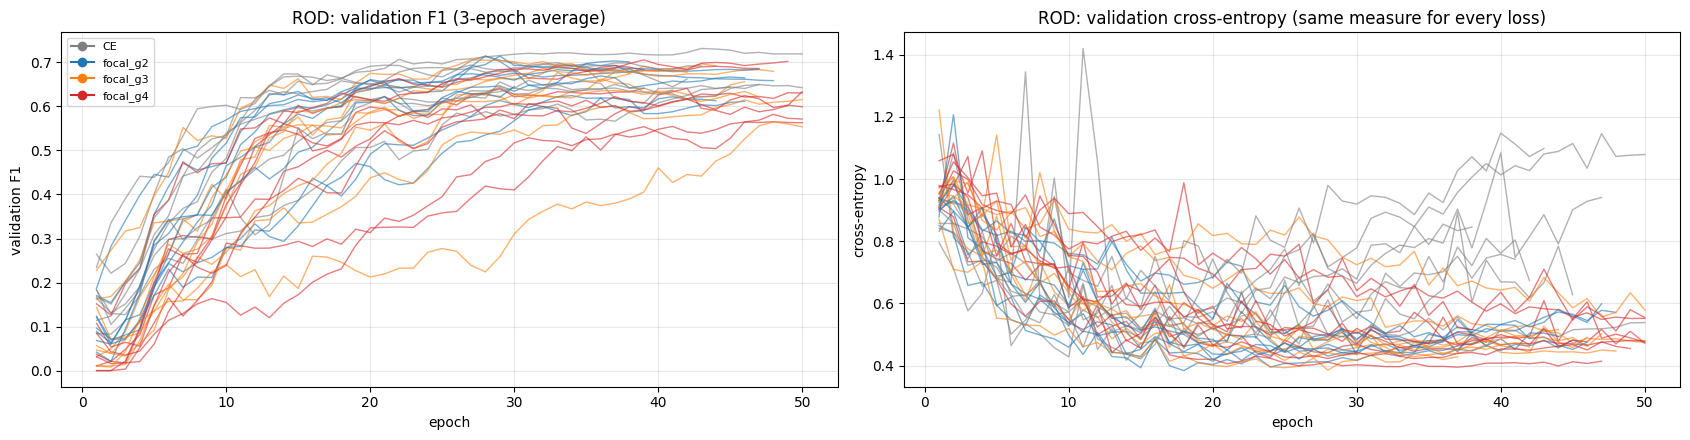

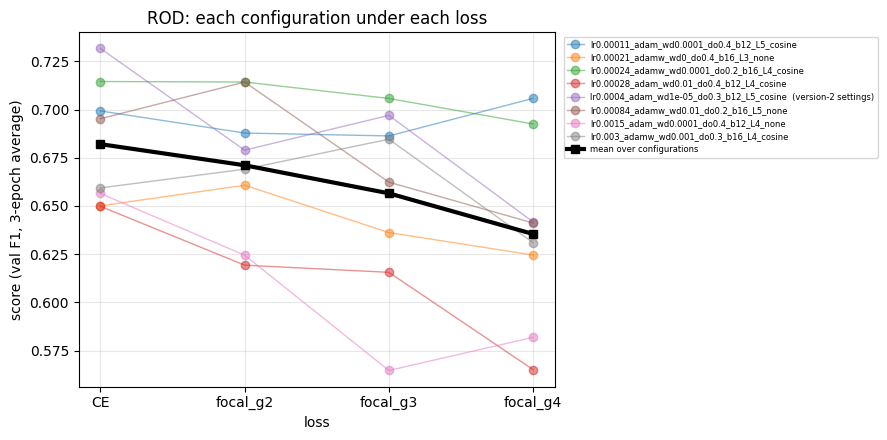

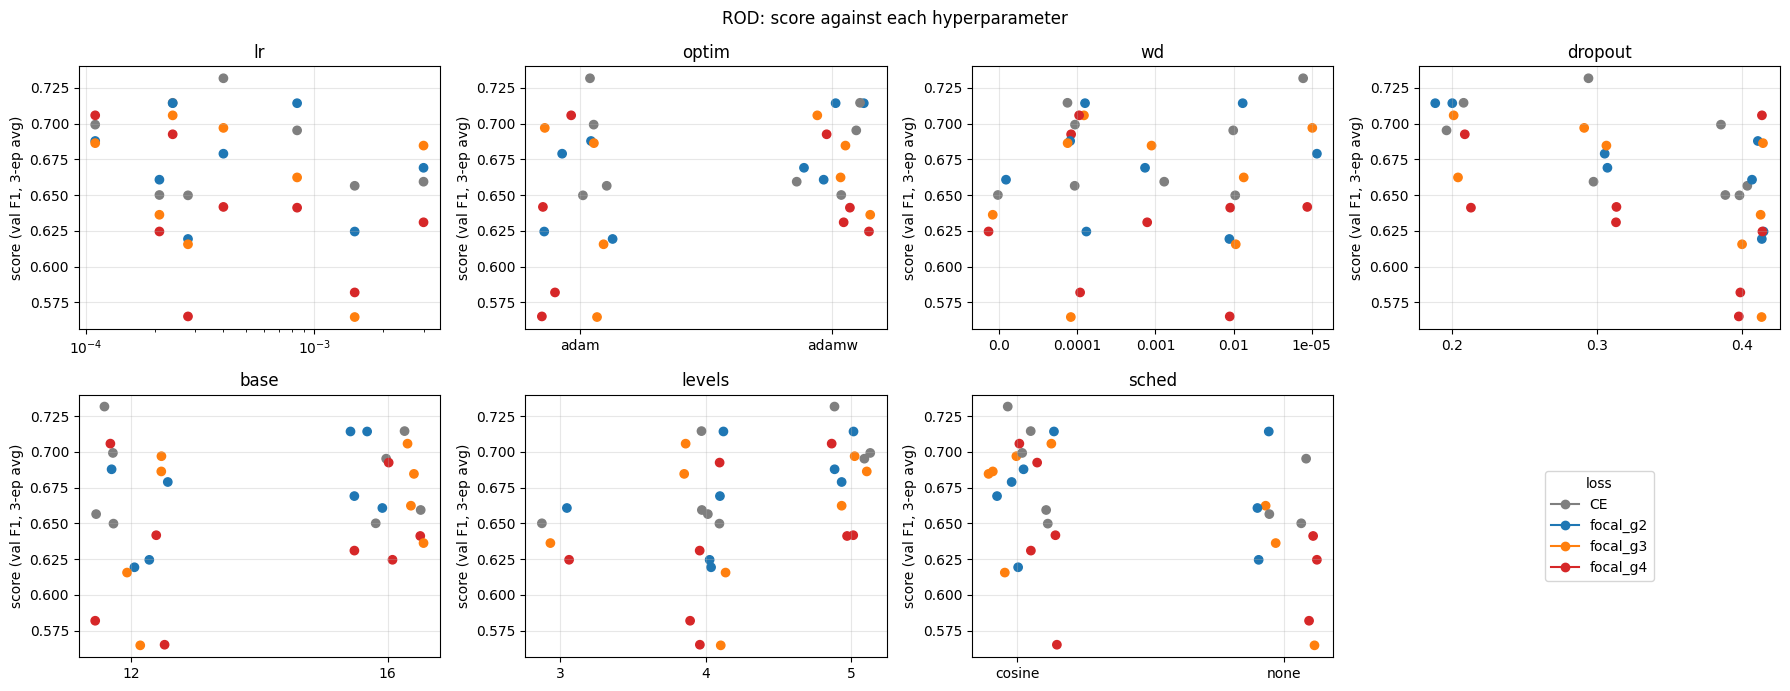

In [13]:
LCOL = dict(zip(LOSSES, ['tab:gray', 'tab:blue', 'tab:orange', 'tab:red']))
L_LEGEND = [Line2D([], [], color=c, marker='o', label=k) for k, c in LCOL.items()]

def plot_search(ds):
    res = RES[ds]; ok = res[res['status'] == 'ok']
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
    for _, r in ok.iterrows():
        h = pd.DataFrame(HIST.get(r['tag'], []))
        if h.empty: continue
        ax[0].plot(h['epoch'], h['val_F1_ma'], color=LCOL[r['loss']], alpha=0.6, lw=1)
        ax[1].plot(h['epoch'], h['val_loss'], color=LCOL[r['loss']], alpha=0.6, lw=1)
    ax[0].set(title=f'{ds}: validation F1 (3-epoch average)', xlabel='epoch', ylabel='validation F1'); ax[0].legend(handles=L_LEGEND, fontsize=8)
    ax[1].set(title=f'{ds}: validation cross-entropy (same measure for every loss)', xlabel='epoch', ylabel='cross-entropy')
    for a in ax: a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    piv = ok.pivot_table(index='config', columns='loss', values='best_val_F1_ma')[[l for l in LOSSES if l in set(ok['loss'])]]
    fig, a = plt.subplots(figsize=(9, 4.5)); x = np.arange(len(piv.columns))
    for k, row in piv.iterrows():
        a.plot(x, row.values, marker='o', alpha=0.5, lw=1, label=k + ('  (version-2 settings)' if k == cfg_key(ANCHOR) else ''))
    a.plot(x, piv.mean().values, 'k-', lw=3, marker='s', label='mean over configurations')
    a.set_xticks(x, piv.columns); a.set(xlabel='loss', ylabel='score (val F1, 3-epoch average)', title=f'{ds}: each configuration under each loss')
    a.grid(alpha=0.3); a.legend(fontsize=6, bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(18, 7)); jit = np.random.default_rng(0)
    for a in axes.ravel()[len(HP):]: a.axis('off')
    for a, k in zip(axes.ravel(), HP):
        colors = [LCOL[l] for l in ok['loss']]
        if k == 'lr':
            a.scatter(ok['lr'], ok['best_val_F1_ma'], c=colors); a.set_xscale('log')
        else:
            cats = sorted(ok[k].astype(str).unique()); pos = {c: i for i, c in enumerate(cats)}
            a.scatter([pos[str(v)] + jit.uniform(-0.15, 0.15) for v in ok[k]], ok['best_val_F1_ma'], c=colors)
            a.set_xticks(range(len(cats)), cats)
        a.set(title=k, ylabel='score (val F1, 3-ep avg)'); a.grid(alpha=0.3)
    axes.ravel()[-1].legend(handles=L_LEGEND, loc='center', title='loss')
    fig.suptitle(f'{ds}: score against each hyperparameter'); plt.tight_layout(); plt.show()

for ds in RES:
    plot_search(ds)

In [14]:
# ---- plotting helpers used in the sections below ----
CMAP = plt.get_cmap('tab10')

def plot_per_class(per_class, frame_df, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
    pc = pd.DataFrame(per_class).T; x = np.arange(len(pc)); w = 0.27
    for k, (m, lab) in enumerate((('P', 'precision'), ('R', 'recall'), ('F1', 'F1'))):
        ax[0].bar(x + (k - 1) * w, pc[m], w, label=lab)
    ax[0].set_xticks(x, [f"{c}\n(n={int(pc.loc[c, 'n_gt'])})" for c in pc.index])
    ax[0].set(title=f'{title}: segment level (IoU ≥ 0.5), per ornament class', xlabel='ornament class (number of ground-truth segments)',
              ylabel='score', ylim=(0, 1)); ax[0].legend(); ax[0].grid(axis='y', alpha=0.3)
    x = np.arange(NC)
    for k, m in enumerate(('precision', 'recall', 'F1')):
        ax[1].bar(x + (k - 1) * w, frame_df[m], w, label=m)
    ax[1].set_xticks(x, CLASSES)
    ax[1].set(title=f'{title}: frame level, all {NC} classes', xlabel='class', ylabel='score', ylim=(0, 1))
    ax[1].legend(); ax[1].grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

def gt_segs(t): return [(s, e, C2I[l]) for s, e, l in t['segs'] if l]
def label_segs(lab, fps): return [(s / fps, e / fps, c) for s, e, c in runs(lab)]

def draw_segments(ax, segs, lo, hi, name):
    for s, e, c in segs:
        if e > lo and s < hi:
            s, e = max(s, lo), min(e, hi)
            ax.axvspan(s, e, color=CMAP(c), alpha=0.85)
            if e - s > 0.15: ax.text((s + e) / 2, 0.5, CLASSES[c], ha='center', va='center', fontsize=7)
    ax.set(yticks=[], xlim=(lo, hi)); ax.set_ylabel(name, rotation=0, ha='right', va='center', fontsize=8)

def class_legend(): return [plt.Rectangle((0, 0), 1, 1, color=CMAP(c), label=CLASSES[c]) for c in range(1, NC)]

def show_example(data, preds, t, t0s, dur, title):
    """Spectrogram, ground truth, then one row per prediction. preds: list of (row name, {recording id: per-frame labels})."""
    fps = t['fps']; a = int(t0s * fps); b = min(len(t['y']), int((t0s + dur) * fps)); lo, hi = a / fps, b / fps
    n = 1 + len(preds)
    fig, ax = plt.subplots(1 + n, 1, figsize=(14, 3 + 0.8 * n), sharex=True, gridspec_kw=dict(height_ratios=[3] + [1] * n))
    ax[0].imshow(data.x[t['id']][:, a:b].float().numpy(), origin='lower', aspect='auto', cmap='magma', extent=[lo, hi, 0, data.n_feat])
    ax[0].set(ylabel='constant-Q bin', title=title)
    draw_segments(ax[1], gt_segs(t), lo, hi, 'ground truth')
    for k, (name, labs) in enumerate(preds):
        draw_segments(ax[2 + k], label_segs(labs[t['id']], fps), lo, hi, name)
    ax[1].legend(handles=class_legend(), ncol=NC - 1, fontsize=7, loc='upper right', bbox_to_anchor=(1, 1.9), title='ornament class', title_fontsize=7)
    ax[-1].set_xlabel('time (s, after removing leading silence)'); plt.tight_layout(); plt.show()

def show_attention(data, model, t, t0s, dur, title):
    fps = t['fps']; a = int(t0s * fps); b = min(len(t['y']), int((t0s + dur) * fps))
    x, _ = data.get(t)
    with torch.no_grad(), torch.autocast('cuda', dtype=AMP_DTYPE):
        _, maps = model(x, return_attention=True)
    att = maps[-1][0].float().cpu().numpy()[:data.n_feat, a:b]          # finest level: (freq, time) at full resolution
    fig, ax = plt.subplots(2, 1, figsize=(14, 4.5), sharex=True)
    ax[0].imshow(data.x[t['id']][:, a:b].float().numpy(), origin='lower', aspect='auto', cmap='magma', extent=[a / fps, b / fps, 0, data.n_feat])
    im = ax[1].imshow(att, origin='lower', aspect='auto', cmap='viridis', vmin=0, vmax=1, extent=[a / fps, b / fps, 0, data.n_feat])
    ax[0].set(ylabel='constant-Q bin', title=title); ax[1].set(ylabel='constant-Q bin', xlabel='time (s)')
    fig.colorbar(im, ax=ax[1], fraction=0.02, pad=0.01, label='attention'); plt.show()

def busiest(tracks, k):
    return sorted(tracks, key=lambda t: -sum(1 for s in t['segs'] if s[2]) / max(t['dur'], 1))[:k]

## 11. Watershed decoding (tuned on validation)

With plain per-frame **argmax** decoding, every unbroken run of one ornament class is a segment. A single frame that flips class therefore splits an ornament in two, and one- or two-frame blips become segments of their own (fragmentation, the main source of false positives in versions 1 and 2). **Watershed decoding** turns the per-frame class probabilities into segments instead. It is the only decoding used in this notebook. It is a 1-D marker-controlled watershed along time:

1. **Smoothing** (optional): the class probabilities are smoothed over time with a Gaussian of width `sigma_s` seconds.
2. **Landscape**: the ornament probability $p_{orn} = 1 - p(\text{none})$ of every frame; the watershed floods the "terrain" $1 - p_{orn}$.
3. **Seeds (markers)**: stretches where **one** ornament class has probability ≥ `t_high` for at least `min_seed_s` seconds. `min_seed_s` is **fixed to the duration of the shortest ornament segment in the training labels** (0.10 s on ROD): no real ornament is shorter, so a shorter confident stretch is treated as noise. Each stretch is one seed. Short or unsure blips do not become seeds, so they cannot create segments of their own.
4. **Flooding**: every seed grows over neighbouring frames as long as $p_{orn}$ ≥ `t_low`. Where the floods of two seeds meet (touching ornaments, very common in ROD, e.g. `Me | H | K` without a gap), the boundary is placed at the least ornament-like frame between them: the watershed line.
5. **Class of each segment**: the ornament class with the highest **mean** probability over the whole segment, so a few wrong frames inside an ornament no longer split it. Touching segments that end up with the same class are merged.

The other three parameters are tuned by grid search on the **validation** recordings **after every epoch of every run** (section 8); the kept epoch's parameters are used for that model. The test set is not used. Validation F1 after tuning is optimistic (it was tuned on those recordings), so the fair comparison is on test (section 14). This section shows the tuning for the best model of each loss.

| parameter | values |
|---|---|
| `t_high` (seed threshold) | 0.5, 0.6, 0.7, 0.8, 0.9 |
| `t_low` (flooding threshold) | 0.2, 0.3, 0.4, 0.5 (≤ `t_high`) |
| `min_seed_s` (shortest seed) | fixed: shortest ornament segment in the training labels |
| `sigma_s` (smoothing) | 0, 0.05, 0.1, 0.2 s |

The functions are defined in the training cell (section 8), because training already uses them.

ROD: validation segment scores with watershed decoding, best model of each loss (tuned on these recordings, so optimistic)


,config,P,R,F1,n_pred,n_gt,t_high,t_low,min_seed_s,sigma_s
loss,,,,,,,,,,
CE,lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine,0.753,0.735,0.744,364,373,0.8,0.5,0.104,0.0
focal_g2,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,0.747,0.681,0.712,340,373,0.6,0.4,0.104,0.0
focal_g3,lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine,0.772,0.670,0.717,324,373,0.6,0.4,0.104,0.0
focal_g4,lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine,0.754,0.684,0.717,338,373,0.6,0.5,0.104,0.0


ROD: the 10 best watershed settings for the selected model (CE)


,t_high,t_low,min_seed_s,sigma_s,val_F1
0,0.8,0.5,0.104,0.0,0.744
1,0.7,0.3,0.104,0.0,0.741
2,0.7,0.5,0.104,0.0,0.740
3,0.8,0.3,0.104,0.0,0.740
4,0.9,0.5,0.104,0.0,0.739
5,0.7,0.4,0.104,0.0,0.735
6,0.8,0.4,0.104,0.0,0.734
7,0.6,0.3,0.104,0.0,0.727
8,0.9,0.3,0.104,0.0,0.727
9,0.6,0.5,0.104,0.0,0.726


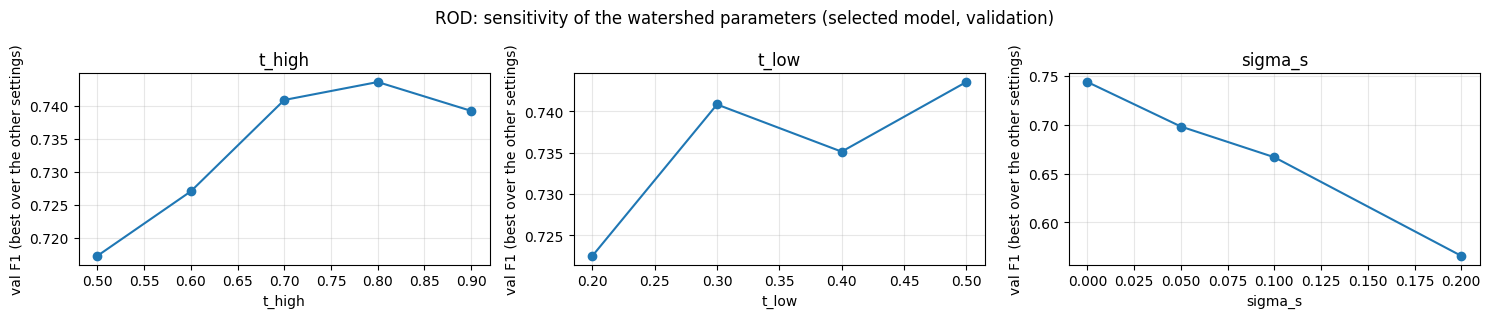

In [15]:
# ---- watershed parameters of the best model of each loss (tuned on validation at its kept epoch, during training) ----
WS_PARAMS, WS_GRIDS, VAL_PROBS = {}, {}, {}
for ds in DATA:
    WS_PARAMS[ds], WS_GRIDS[ds], rows = {}, {}, []
    vt = DATA[ds].tracks['val']
    for l, b in BEST_PER_LOSS[ds].items():
        model = load_model(b['tag']); VAL_PROBS[(ds, l)] = probs = predict_proba(model, DATA[ds], vt)
        del model; torch.cuda.empty_cache()
        WS_PARAMS[ds][l] = b['ws_params']
        _, WS_GRIDS[ds][l] = tune_watershed(probs, vt, MIN_SEED_S[ds])      # the full grid again, for the tables and plots
        m, _ = evaluate(ws_decode_all(probs, vt, **WS_PARAMS[ds][l]), vt)
        rows.append(dict(loss=l, config=b['key'], **{k: m[k] for k in ('P', 'R', 'F1', 'n_pred', 'n_gt')}, **WS_PARAMS[ds][l]))
    print(f'{ds}: validation segment scores with watershed decoding, best model of each loss (tuned on these recordings, so optimistic)')
    display(pd.DataFrame(rows).set_index('loss').round(3))
    sel = SELECTED[ds]['loss']; g = WS_GRIDS[ds][sel]
    print(f'{ds}: the 10 best watershed settings for the selected model ({sel})'); display(g.head(10).round(3))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
    for a, k in zip(ax, ('t_high', 't_low', 'sigma_s')):
        s = g.groupby(k)['val_F1'].max(); a.plot(s.index, s.values, 'o-')
        a.set(title=k, xlabel=k, ylabel='val F1 (best over the other settings)'); a.grid(alpha=0.3)
    fig.suptitle(f'{ds}: sensitivity of the watershed parameters (selected model, validation)')
    plt.tight_layout(); plt.show()
json.dump(WS_PARAMS, open(OUT / 'watershed_params.json', 'w'), indent=1)


## 12. Training progress of the selected model (epoch-wise images)

During training, after **every epoch**, the predicted class probabilities on the first 25 s of two fixed validation recordings (the two with the most ornaments per second) were stored in `runs/<tag>_epochs.npz`, for every run. Here they are drawn for the **selected model**, one image per epoch and recording, saved to `rod_koopman/unet_seg_v3/epoch_images/<recording>/epoch_NNN.png`. Each image shows:

* the spectrogram, the ground truth and the **watershed** prediction (with the parameters tuned on validation after that epoch);
* the probability of every class over time (dashed grey: `none`), which shows what the model is unsure about;
* the epoch's validation F1, and a mark on the epoch whose weights were kept.

Below the saving step, an overview shows the watershed prediction for one recording after selected epochs, one row per epoch, so the whole training can be seen at a glance.

ROD: 50 epoch images saved to /kaggle/working/unet_seg_v3/epoch_images/001_bhoopali_4_Antra_2nd_line
ROD: 50 epoch images saved to /kaggle/working/unet_seg_v3/epoch_images/002_bhairav6_Bhairav_Palta_2_Ekgun_Aakar


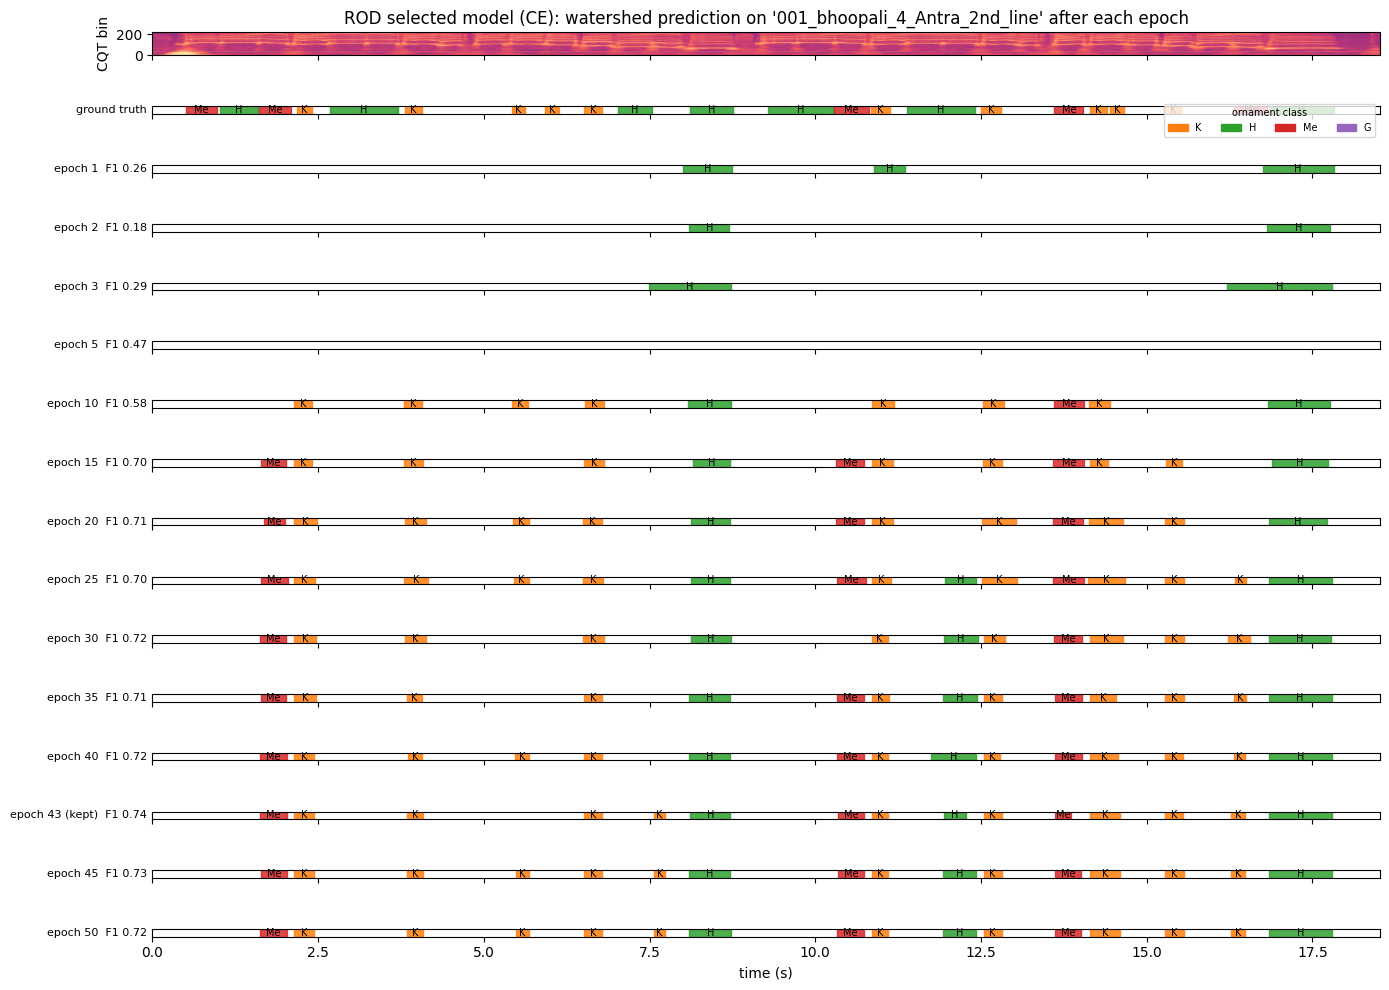

In [16]:
def epoch_image(data, t, P, ep, h, kept, ws_p, path):
    fps = data.fps; T = P.shape[1]; hi = T / fps; tt = np.arange(T) / fps
    fig, ax = plt.subplots(4, 1, figsize=(14, 6.8), sharex=True, gridspec_kw=dict(height_ratios=[3, 1, 1, 2]))
    ax[0].imshow(data.x[t['id']][:, :T].float().numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, hi, 0, data.n_feat])
    ax[0].set(ylabel='CQT bin', title=f"'{t['id']}' | epoch {ep} | val F1 {h['val_F1']:.3f} (3-epoch avg {h['val_F1_ma']:.3f}) | "
                                      f"train loss {h['train_loss']:.3f}" + ('  | WEIGHTS KEPT FROM THIS EPOCH' if kept else ''))
    draw_segments(ax[1], gt_segs(t), 0, hi, 'ground truth')
    draw_segments(ax[2], label_segs(watershed_decode(P, fps, **ws_p), fps), 0, hi, 'watershed')
    for c in range(1, NC): ax[3].plot(tt, P[c], color=CMAP(c), lw=0.9, label=CLASSES[c])
    ax[3].plot(tt, P[0], color='0.5', lw=0.7, ls='--', label='none')
    ax[3].set(ylim=(0, 1), xlim=(0, hi), ylabel='probability', xlabel='time (s)'); ax[3].legend(ncol=NC, fontsize=7, loc='upper right')
    plt.tight_layout(); fig.savefig(path, dpi=80); plt.close(fig)

def ws_of_epoch(h, ds):   # the watershed parameters tuned on validation after that epoch
    return dict(t_high=h['ws_t_high'], t_low=h['ws_t_low'], sigma_s=h['ws_sigma_s'], min_seed_s=MIN_SEED_S[ds])

for ds in DATA:
    sel = SELECTED[ds]; tag = sel['tag']; f = RUNS / f'{tag}_epochs.npz'
    if not f.exists():
        print(f'{ds}: no stored epoch predictions for {tag}'); continue
    z = np.load(f); ids = [str(i) for i in z['ids']]; rj = json.loads((RUNS / f'{tag}.json').read_text())
    hist, kept = rj['hist'], rj['best_epoch']; tr = {t['id']: t for t in DATA[ds].tracks['val']}
    for i, rid in enumerate(ids):
        P_all = z[f'probs{i}'].astype(np.float32); d = OUT / 'epoch_images' / rid; d.mkdir(parents=True, exist_ok=True)
        for e in range(len(P_all)):
            epoch_image(DATA[ds], tr[rid], P_all[e], e + 1, hist[e], e + 1 == kept, ws_of_epoch(hist[e], ds), d / f'epoch_{e + 1:03d}.png')
        print(f'{ds}: {len(P_all)} epoch images saved to {d}')
    # ---- overview: watershed prediction on the first example recording after selected epochs ----
    P_all = z['probs0'].astype(np.float32); t = tr[ids[0]]; E, fps = len(P_all), DATA[ds].fps; hi = P_all.shape[2] / fps
    show = sorted({e for e in [1, 2, 3, 5, *range(10, E + 1, 5), kept, E] if 1 <= e <= E})
    fig, ax = plt.subplots(len(show) + 2, 1, figsize=(14, 2.5 + 0.5 * (len(show) + 1)), sharex=True,
                           gridspec_kw=dict(height_ratios=[3] + [1] * (len(show) + 1)))
    ax[0].imshow(DATA[ds].x[t['id']][:, :P_all.shape[2]].float().numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, hi, 0, DATA[ds].n_feat])
    ax[0].set(ylabel='CQT bin', title=f"{ds} selected model ({sel['loss']}): watershed prediction on '{ids[0]}' after each epoch")
    draw_segments(ax[1], gt_segs(t), 0, hi, 'ground truth')
    for a, e in zip(ax[2:], show):
        draw_segments(a, label_segs(watershed_decode(P_all[e - 1], fps, **ws_of_epoch(hist[e - 1], ds)), fps), 0, hi, f"epoch {e}{' (kept)' if e == kept else ''}  F1 {hist[e - 1]['val_F1']:.2f}")
    ax[1].legend(handles=class_legend(), ncol=NC - 1, fontsize=7, loc='upper right', bbox_to_anchor=(1, 1.9), title='ornament class', title_fontsize=7)
    ax[-1].set_xlabel('time (s)'); plt.tight_layout(); plt.show()

## 13. Selected model on the validation set: receptive field, per-class results, example predictions and attention maps

For the overall selected model (best configuration and loss on validation): the measured temporal receptive field, per-class precision, recall and F1 on the **validation** recordings with watershed decoding, predicted vs ground-truth ornaments on two example recordings, and the **attention map of the finest skip connection** (where the attention gate lets encoder detail through to the decoder: 1 = passed, 0 = suppressed).

ROD selected model (ROD_attres_lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine_CE_s2035): receptive field 4.12 s; 90% of the influence within 1.49 s
ROD selected model, VALIDATION, watershed: {'P': 0.753, 'R': 0.735, 'F1': 0.744, 'F1_any': 0.744, 'F1_iou30': 0.771, 'IoU_macro': 0.622, 'IoU_orn': 0.657, 'IoU_matched': 0.821, 'seg_jaccard': 0.592, 'boundary_acc': 0.499, 'frame_acc': 0.84, 'n_pred': 364.0, 'n_gt': 373.0}


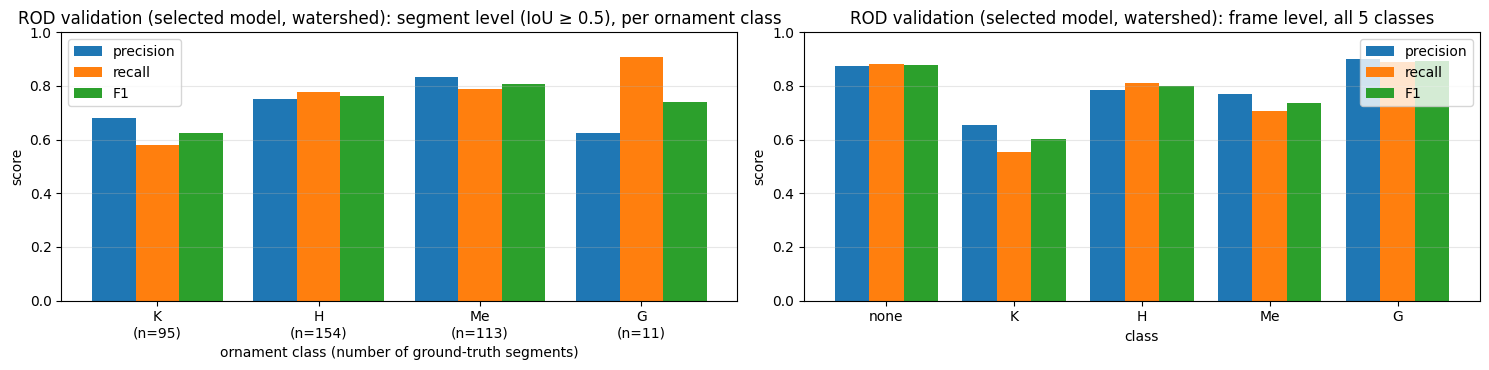

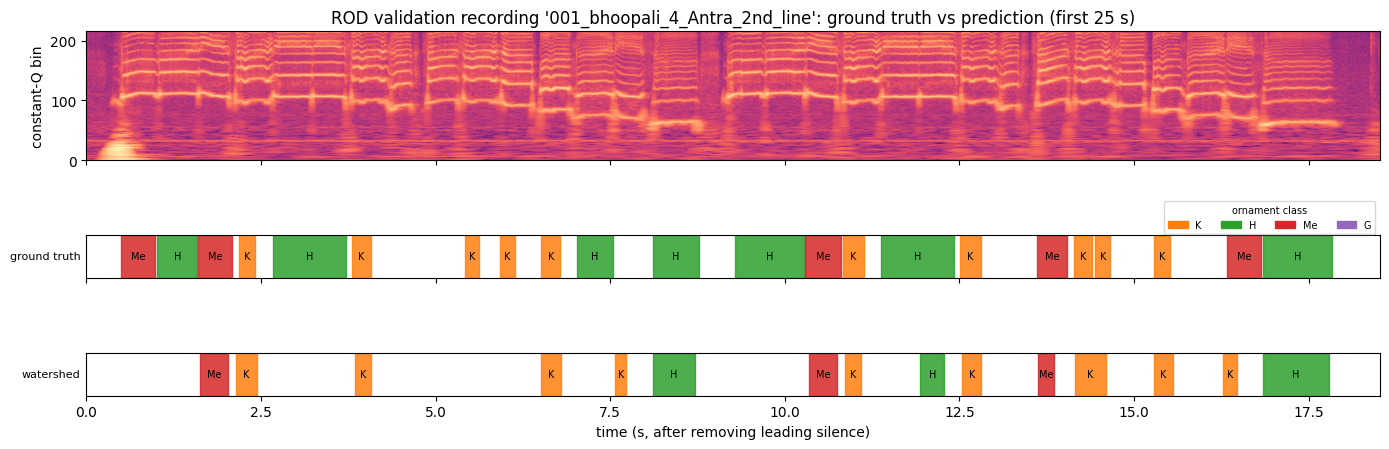

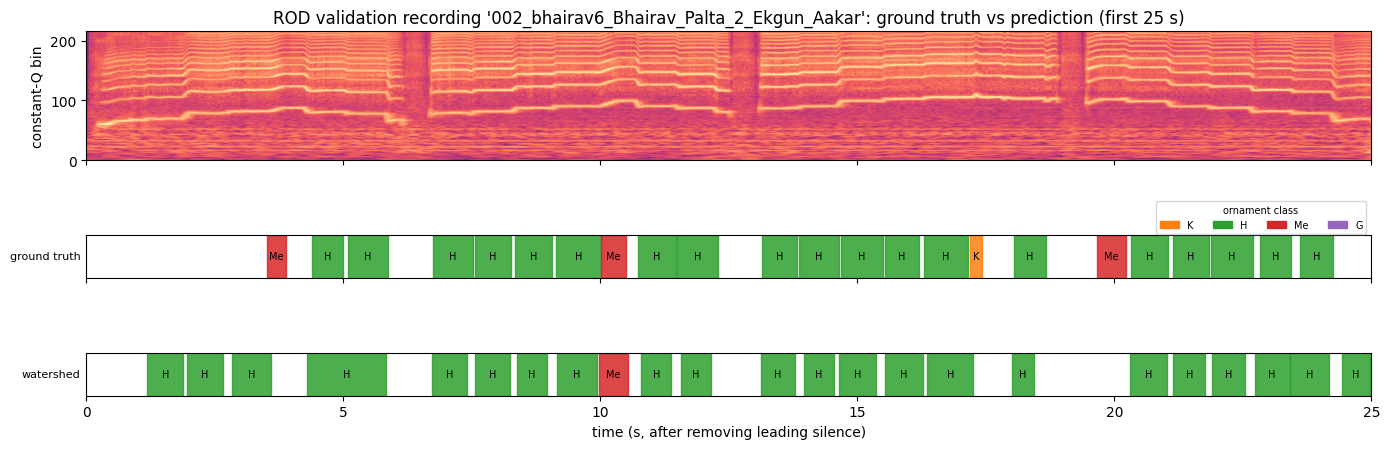

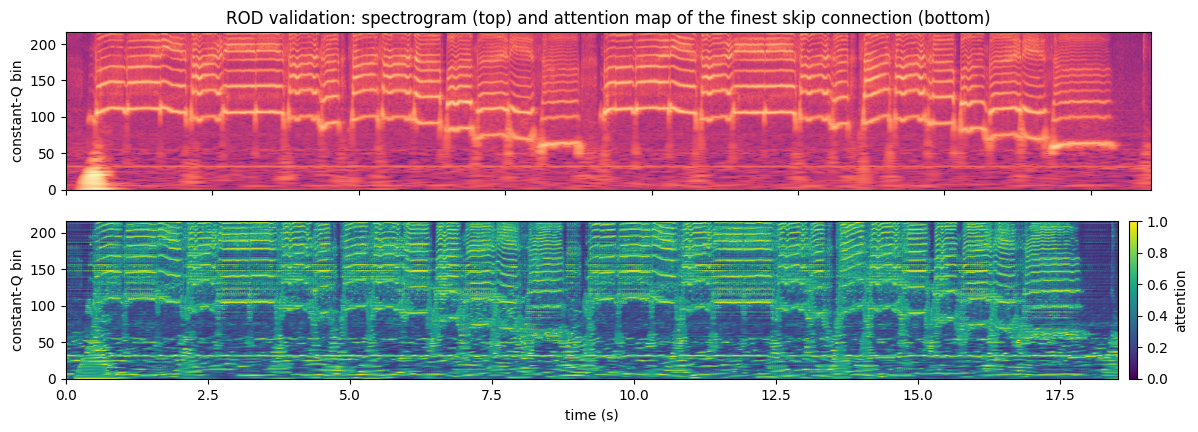

In [17]:
VAL_LABS, VAL_WS = {}, {}
for ds in DATA:
    sel = SELECTED[ds]; tag = sel['tag']; vt = DATA[ds].tracks['val']
    rf = receptive_field(load_model(tag), DATA[ds], vt)
    edge = f" - reaches the edge of the {rf['window_s']:.0f} s measuring window" if rf['reaches_window_edge'] else ''
    print(f"{ds} selected model ({tag}): receptive field {rf['theoretical_s']:.2f} s{edge}; 90% of the influence within {rf['effective90_s']:.2f} s")
    torch.cuda.empty_cache()
    probs = VAL_PROBS[(ds, sel['loss'])]
    VAL_WS[ds] = ws_decode_all(probs, vt, **WS_PARAMS[ds][sel['loss']])
    for name, labs in (('watershed', VAL_WS[ds]),):
        m, pc = evaluate(labs, vt); fr, _ = frame_report(labs, vt)
        print(f'{ds} selected model, VALIDATION, {name}:', {k: round(float(v), 3) for k, v in m.items()})
        plot_per_class(pc, fr, f'{ds} validation (selected model, {name})')
    for t in busiest(vt, 2):
        show_example(DATA[ds], [('watershed', VAL_WS[ds])], t, 0.0, 25.0,
                     f"{ds} validation recording '{t['id']}': ground truth vs prediction (first 25 s)")
    model = load_model(tag)
    show_attention(DATA[ds], model, busiest(vt, 1)[0], 0.0, 25.0,
                   f"{ds} validation: spectrogram (top) and attention map of the finest skip connection (bottom)")
    del model; torch.cuda.empty_cache()

## 14. Final test evaluation (held-out test recordings)

All choices above were made on validation scores only. Here the **best model of each loss** (its configuration chosen on validation) is run **once** on the test recordings, with **watershed decoding**, using the parameters tuned on validation for the kept epoch of that model. These numbers are only reported: nothing is selected or changed afterwards (the overall selected model was already fixed on validation in section 9). Each is a single seed, so differences of a few points between losses are within run-to-run noise (in version 2 the seed-to-seed standard deviation of validation F1 was about ±0.03).

For comparison, the version-2 selected model (U-Net + TCN, cross-entropy, argmax) is listed with its **seed-`SEED`** result (the same single-seed situation) and its mean over 3 seeds, read from `rod_koopman/unet_seg_v2/final_results.json` if that file exists.

The overall selected model is saved as `rod_koopman/unet_seg_v3/best_unet_ROD.pt`, with its settings and normalisation statistics; its watershed parameters are in `watershed_params.json`.

In [18]:
TEST, TEST_LABS, TEST_WS = {}, {}, {}
DECODERS = ('watershed',)
cols = ['P', 'R', 'F1', 'IoU_macro', 'IoU_orn', 'IoU_matched', 'seg_jaccard', 'F1_any', 'F1_iou30', 'boundary_acc', 'frame_acc', 'n_pred', 'n_gt']
rows = {}
for ds in DATA:
    TEST[ds] = {}; tt, vt = DATA[ds].tracks['test'], DATA[ds].tracks['val']
    for l, b in BEST_PER_LOSS[ds].items():
        model = load_model(b['tag'])
        probs = predict_proba(model, DATA[ds], tt); _, test_loss = predict(model, DATA[ds], tt)
        del model; torch.cuda.empty_cache()
        vprobs, ws_p = VAL_PROBS[(ds, l)], WS_PARAMS[ds][l]
        dec = dict(watershed=(ws_decode_all(probs, tt, **ws_p), ws_decode_all(vprobs, vt, **ws_p)))
        sel = l == SELECTED[ds]['loss']
        TEST[ds][l] = dict(best_for_loss=b, watershed_params=ws_p, test_CE=test_loss)
        for name, (labs, vlabs) in dec.items():
            m, pc = evaluate(labs, tt); fr, cm = frame_report(labs, tt); vm, _ = evaluate(vlabs, vt)
            TEST[ds][l][name] = dict(val=vm, test=m, test_per_class_segment=pc, test_per_class_frame=fr.to_dict('index'),
                                     test_confusion_frames=cm.tolist())
            for sp, mm in (('validation', vm), ('test', m)):
                rows[f"{ds} v3 {l}{' (selected)' if sel else ''}, {name}: {sp}"] = {k: float(mm[k]) for k in cols}
        if sel:
            TEST_WS[ds] = dec['watershed'][0]
            torch.save(torch.load(RUNS / f"{b['tag']}.pt", map_location='cpu', weights_only=False), OUT / f'best_unet_{ds}.pt')
    v2f = (next(KAGGLE_IN.rglob('v2_final_results.json'), Path('missing')) if KAGGLE
           else PROJ / 'rod_koopman' / 'unet_seg_v2' / 'final_results.json')
    if v2f.exists():
        v2 = json.loads(v2f.read_text()).get(ds)
        if v2:
            s0 = next((s for s in v2['seeds'] if s['tag'].endswith(f'_s{SEED}')), v2['seeds'][0])
            for sp, key in (('validation', 'val'), ('test', 'test')):
                rows[f'{ds} v2 (U-Net + TCN, CE, argmax), seed {SEED}: {sp}'] = {k: float(s0[key][k]) for k in cols}
                rows[f'{ds} v2 (U-Net + TCN, CE, argmax), mean of {len(v2["seeds"])} seeds: {sp}'] = {
                    k: float(np.mean([s[key][k] for s in v2['seeds']])) for k in cols}

tab = pd.DataFrame(rows).T.rename(columns=dict(P='precision', R='recall', IoU_macro='IoU (macro, per class)', IoU_orn='IoU (ornament vs none)',
                                               IoU_matched='IoU (matched segments)', seg_jaccard='segment Jaccard TP/(TP+FP+FN)'))
print('Best configuration per loss (chosen on validation):', {ds: {l: b['key'] for l, b in BEST_PER_LOSS[ds].items()} for ds in BEST_PER_LOSS})
print('(validation rows for watershed are optimistic: its parameters were tuned on the validation recordings)')
display(tab.round(3))
tab.to_csv(OUT / 'test_results.csv')
for ds in TEST:
    for l, r in TEST[ds].items():
        print(f'{ds} TEST, {l}: per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), watershed')
        display(pd.concat({n: pd.DataFrame(r[n]['test_per_class_segment']).T for n in DECODERS}, axis=1).round(3))
    s = TEST[ds][SELECTED[ds]['loss']]
    print(f"{ds} TEST, selected model ({SELECTED[ds]['loss']}): per class (frame level), watershed")
    display(pd.concat({n: pd.DataFrame(s[n]['test_per_class_frame']).T for n in DECODERS}, axis=1).round(3))
json.dump(dict(selected=SELECTED, watershed_params=WS_PARAMS, results=TEST), open(OUT / 'final_results.json', 'w'), indent=1, default=float)
print('saved:', OUT / 'test_results.csv', '|', OUT / 'final_results.json', '|', [str(OUT / f'best_unet_{ds}.pt') for ds in TEST])

Best configuration per loss (chosen on validation): {'ROD': {'CE': 'lr0.0004_adam_wd1e-05_do0.3_b12_L5_cosine', 'focal_g2': 'lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine', 'focal_g3': 'lr0.00024_adamw_wd0.0001_do0.2_b16_L4_cosine', 'focal_g4': 'lr0.00011_adam_wd0.0001_do0.4_b12_L5_cosine'}}
(validation rows for watershed are optimistic: its parameters were tuned on the validation recordings)


,precision,recall,F1,"IoU (macro, per class)",IoU (ornament vs none),IoU (matched segments),segment Jaccard TP/(TP+FP+FN),F1_any,F1_iou30,boundary_acc,frame_acc,n_pred,n_gt
"ROD v3 CE (selected), watershed: validation",0.753,0.735,0.744,0.622,0.657,0.821,0.592,0.744,0.771,0.499,0.840,364.000,373.0
"ROD v3 CE (selected), watershed: test",0.600,0.661,0.629,0.587,0.669,0.831,0.459,0.640,0.694,0.471,0.848,970.000,881.0
"ROD v3 focal_g2, watershed: validation",0.747,0.681,0.712,0.602,0.665,0.837,0.553,0.715,0.760,0.485,0.844,340.000,373.0
"ROD v3 focal_g2, watershed: test",0.634,0.636,0.635,0.580,0.667,0.824,0.465,0.643,0.687,0.426,0.850,883.000,881.0
"ROD v3 focal_g3, watershed: validation",0.772,0.670,0.717,0.596,0.660,0.830,0.559,0.723,0.763,0.432,0.843,324.000,373.0
"ROD v3 focal_g3, watershed: test",0.640,0.600,0.619,0.575,0.665,0.820,0.449,0.625,0.686,0.390,0.853,827.000,881.0
"ROD v3 focal_g4, watershed: validation",0.754,0.684,0.717,0.598,0.661,0.834,0.559,0.726,0.759,0.464,0.846,338.000,373.0
"ROD v3 focal_g4, watershed: test",0.583,0.599,0.591,0.551,0.637,0.820,0.420,0.595,0.666,0.406,0.840,905.000,881.0
"ROD v2 (U-Net + TCN, CE, argmax), seed 2035: validation",0.608,0.689,0.646,0.561,0.646,0.823,0.477,0.653,0.691,0.469,0.837,423.000,373.0
"ROD v2 (U-Net + TCN, CE, argmax), mean of 3 seeds: validation",0.571,0.672,0.616,0.578,0.656,0.831,0.446,0.623,0.675,0.458,0.837,441.333,373.0


ROD TEST, CE: per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), watershed


watershed                                      
           P      R     F1 frame_IoU   n_gt n_pred
K      0.476  0.527  0.500     0.346  241.0  267.0
H      0.639  0.767  0.697     0.710  360.0  432.0
Me     0.673  0.676  0.674     0.524  256.0  257.0
G      0.429  0.250  0.316     0.769   24.0   14.0

ROD TEST, focal_g2: per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), watershed


watershed                                      
           P      R     F1 frame_IoU   n_gt n_pred
K      0.597  0.485  0.535     0.346  241.0  196.0
H      0.654  0.703  0.677     0.721  360.0  387.0
Me     0.645  0.695  0.669     0.522  256.0  276.0
G      0.500  0.500  0.500     0.733   24.0   24.0

... (3 outputs left out)

watershed                                      
           P      R     F1 frame_IoU   n_gt n_pred
K      0.534  0.427  0.475     0.307  241.0  193.0
H      0.616  0.731  0.668     0.701  360.0  427.0
Me     0.606  0.613  0.610     0.481  256.0  259.0
G      0.192  0.208  0.200     0.717   24.0   26.0

ROD TEST, selected model (CE): per class (frame level), watershed


watershed                                           
     precision recall     F1    IoU gt_frames pred_frames
none     0.899  0.884  0.891  0.804  121406.0    119368.0
K        0.485  0.546  0.514  0.346    6140.0      6912.0
H        0.809  0.852  0.830  0.710   39067.0     41127.0
Me       0.693  0.683  0.688  0.524   15024.0     14811.0
G        0.932  0.815  0.869  0.769    4615.0      4034.0

saved: /kaggle/working/unet_seg_v3/test_results.csv | /kaggle/working/unet_seg_v3/final_results.json | ['/kaggle/working/unet_seg_v3/best_unet_ROD.pt']


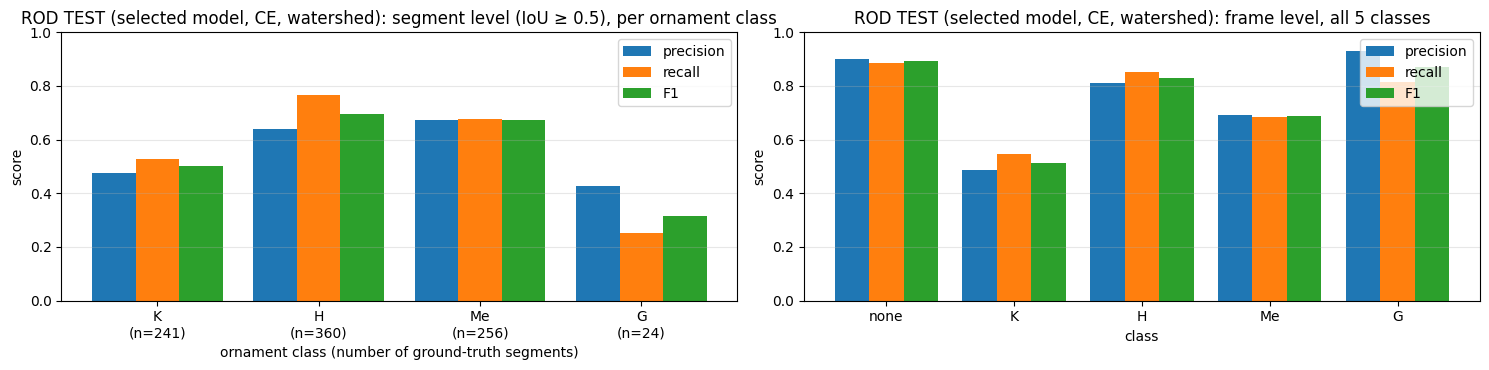

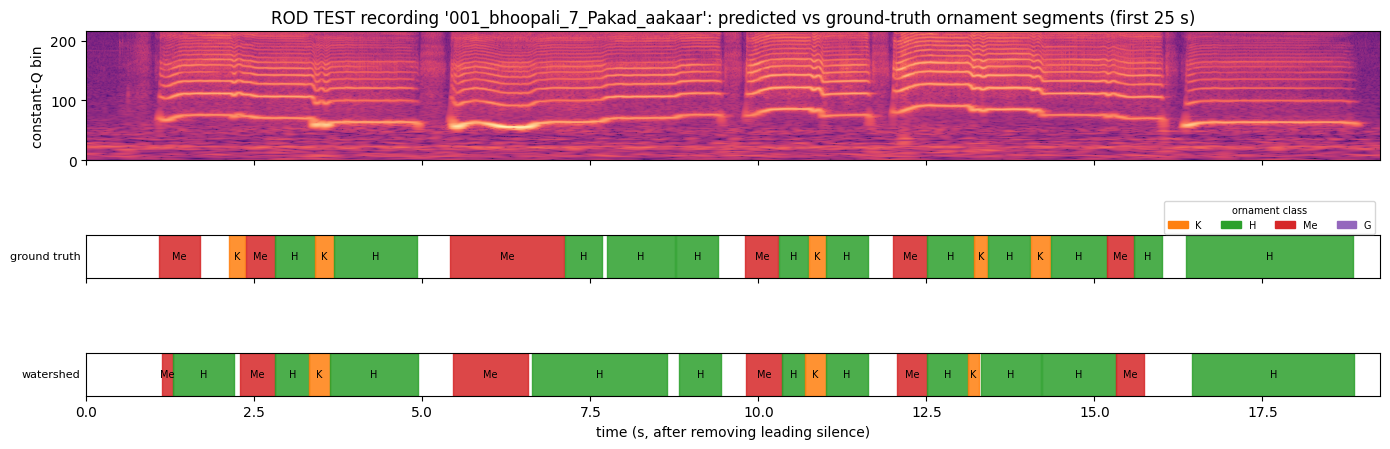

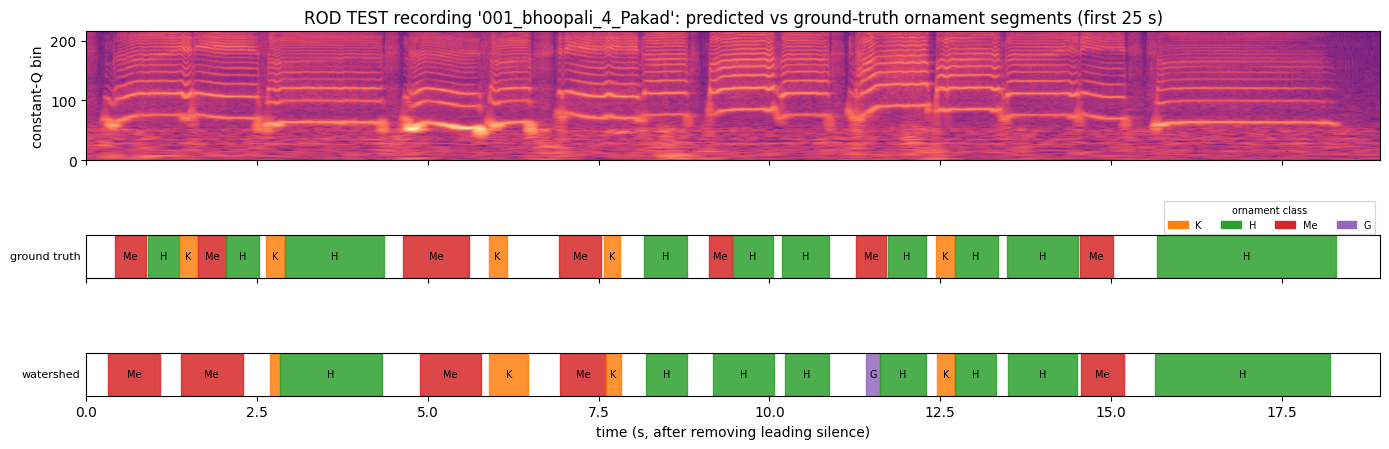

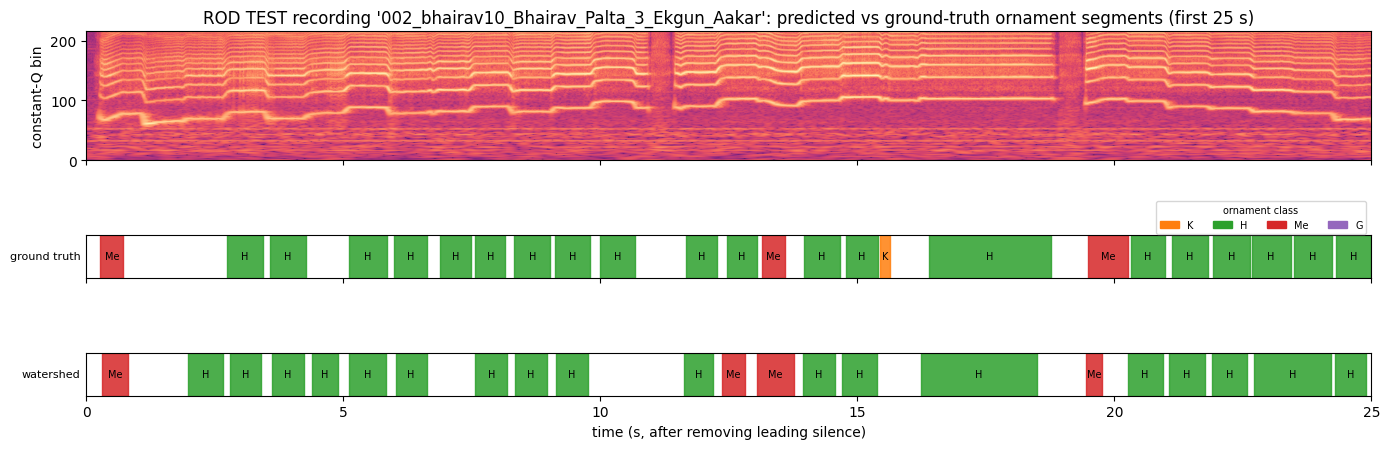

In [19]:
for ds in TEST:
    s = TEST[ds][SELECTED[ds]['loss']]
    for name in DECODERS:
        plot_per_class(s[name]['test_per_class_segment'], pd.DataFrame(s[name]['test_per_class_frame']).T,
                       f"{ds} TEST (selected model, {SELECTED[ds]['loss']}, {name})")
    for t in busiest(DATA[ds].tracks['test'], 3):
        show_example(DATA[ds], [('watershed', TEST_WS[ds])], t, 0.0, 25.0,
                     f"{ds} TEST recording '{t['id']}': predicted vs ground-truth ornament segments (first 25 s)")

## Notes

* **Data**: only the saved ROD cache is used, with the original split (lists saved in `splits.json`). `Mu` and `An` are relabelled as `none` (5 classes). Preprocessing is unchanged from version 2.
* **Model**: Attention Residual U-Net (residual blocks everywhere, additive attention gates on the skip connections), full-frequency output convolution, no temporal module.
* **Loss**: multi-class cross-entropy vs focal loss (γ = 2, 3, 4), no class weights. Every configuration is trained with all four losses.
* **Decoding**: 1-D watershed only, thresholds tuned on validation after every epoch; its F1 is used for checkpointing, the search and the test results.
* **Epoch-wise images**: `epoch_images/<recording>/epoch_NNN.png` for the selected model (from the per-epoch predictions stored for every run in `runs/*_epochs.npz`).
* **Selection**: 8 configurations × 4 losses, one seed each; the best configuration per loss and the overall best are chosen on validation only. The test set is used once, at the end, for the best model of each loss.
* **Comparison with version 2**: version 2's selected model used a U-Net + TCN and was averaged over 3 seeds; the fair single-seed comparison is its seed-`SEED` result, listed in the test table.
* **Saved outputs** (`rod_koopman/unet_seg_v3/`): `runs/*.json` and `runs/*.pt` (every run), `search_results_ROD.csv`, `search_results_all.csv`, `selected_models.json`, `splits.json`, `watershed_params.json`, `epoch_images/`, `best_unet_ROD.pt`, `test_results.csv` and `final_results.json`.
* **Memory / failures**: configurations that need more than the 4 GB of GPU memory are run with spill into shared system RAM and flagged `uses_shared_memory`. Out-of-memory errors and other failed runs are marked in the tables with their error message.